In [7]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, roc_curve
import matplotlib.pyplot as plt
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy.stats import chi2

from ctypes.macholib.dyld import dyld_framework_path

import matplotlib.pyplot as plt
import seaborn as sns

from numpy.ma.core import count
from prompt_toolkit.key_binding.bindings.named_commands import yank_pop
import matplotlib#.pyplot as plt
from matplotlib.font_manager import FontProperties
from html.parser import incomplete


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

from numpy.ma.core import count
from prompt_toolkit.key_binding.bindings.named_commands import yank_pop
import matplotlib#.pyplot as plt

warnings.filterwarnings('ignore')
# Все библиотеки

import numpy as np
import pandas as pd
import scipy.stats as stats
from scipy.stats import ttest_ind, levene, mannwhitneyu,shapiro, \
    f_oneway, kruskal, chi2_contingency, fisher_exact
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib.pyplot as plt
import seaborn as sns

import sys
import os
from matplotlib import rcParams
from matplotlib import font_manager as fm
import matplotlib as mpl
import warnings


In [8]:
df = pd.read_excel("База Нижний Новгород.xlsx")

In [9]:
df

,id,year,gender,faculty,teaching_position,position_head,HSE_start,experience_uni,bachelor,specialist,...,courses_master,courses_minor,courses_magolego,courses_elective,thesis_bachelor,thesis_master,PhD_students,PhD_finished,best_teacher,best_teacher_previous
0,100,y24_25,M,econ,профессор,1,1998,27.0,NaN,1998,...,1,0,1,0,3,2,2,8,0,6
1,100,y23_24,M,econ,профессор,1,1998,26.0,NaN,1998,...,1,0,1,0,5,0,2,8,0,6
2,100,y22_23,M,econ,профессор,1,1998,25.0,NaN,1998,...,1,0,1,0,0,4,1,8,0,6
3,101,y24_25,M,econ,доцент,1,2006,14.0,2005,NaN,...,0,0,0,0,0,0,1,0,0,2
4,101,y23_24,M,econ,доцент,1,2006,13.0,2005,NaN,...,0,0,0,0,0,0,1,0,0,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2482,927,y23_24,M,math,профессор,0,2017,38.0,NaN,1976,...,0,0,0,0,0,1,0,0,0,3
2483,927,y22_23,M,math,профессор,0,2017,37.0,NaN,1976,...,1,0,1,0,0,2,0,0,0,3
2484,928,y24_25,M,math,профессор,1,2011,8.0,NaN,1990,...,0,0,0,0,1,0,0,0,0,0
2485,928,y23_24,M,math,профессор,1,2011,7.0,NaN,1990,...,0,0,0,0,0,0,0,0,0,0


Formula: y ~ C(gender) + C(faculty) + C(teaching_position) + C(year) + publications_english + HSE_graduate + position_head + deg_has_candidate + deg_has_doctor + deg_has_phd + experience_uni + publications_papers_5years + publications_other_5years + paper_award + courses_total + courses_bachelor + courses_master + courses_minor + courses_magolego + courses_elective + thesis_bachelor + thesis_master + PhD_students + PhD_finished
                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                 1740
Model:                          Logit   Df Residuals:                     1708
Method:                           MLE   Df Model:                           31
Date:                Sun, 12 Oct 2025   Pseudo R-squ.:                  0.1154
Time:                        11:44:23   Log-Likelihood:                -694.93
converged:                       True   LL-Null:                       -785.58
Covariance Type

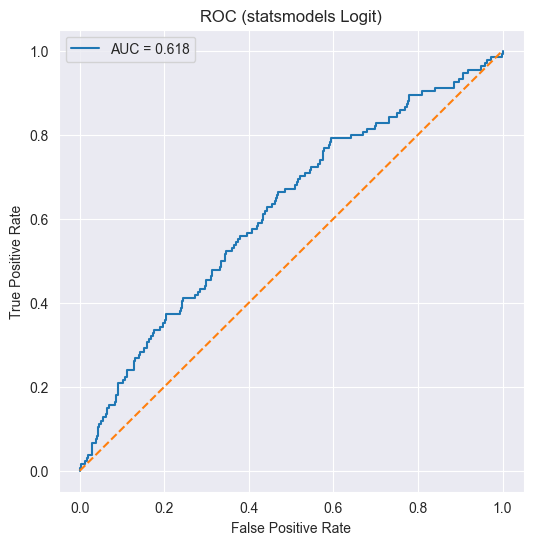

Hosmer–Lemeshow: stat=35.000, p=0.000

VIF (числовые):
                   Feature       VIF
                     const  5.150059
            experience_uni  1.228402
publications_papers_5years  1.653313
 publications_other_5years  1.413210
               paper_award  1.157607
             courses_total 17.505420
          courses_bachelor  8.157181
            courses_master  9.182867
             courses_minor  1.661581
          courses_magolego  5.580486
          courses_elective  1.112529
           thesis_bachelor  1.146180
             thesis_master  1.680523
              PhD_students  1.469024
              PhD_finished  1.428846

Топ-20 по |коэфф|:
                                                        coef  importance
C(teaching_position)[T.приглашенный преподаватель] -3.682765    3.682765
C(teaching_position)[T.ассистент]                  -2.553056    2.553056
Intercept                                          -1.597463    1.597463
C(teaching_position)[T.старший преподават

In [10]:
# ===================== LOGIT (statsmodels, формулы, кластер-SE, анти-коллинеарность) =====================
import pandas as pd
import numpy as np
import re, warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)

import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, \
    confusion_matrix, precision_recall_curve, roc_curve
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy.stats import chi2
import matplotlib.pyplot as plt

# --- helpers ---
def collapse_rare_levels(s: pd.Series, min_count=20, other_label='Other'):
    vc = s.value_counts(dropna=False)
    rare = vc[vc < min_count].index
    return s.where(~s.isin(rare), other_label)

def bin_flag(col: pd.Series, pattern: str):
    return col.fillna("").astype(str).str.contains(pattern, flags=re.IGNORECASE, regex=True).astype(int)

def hosmer_lemeshow(y_true, y_prob, g=10):
    data = pd.DataFrame({'y': y_true, 'prob': y_prob})
    data['group'] = pd.qcut(data['prob'], g, duplicates='drop')
    obs = data.groupby('group', observed=False)['y'].agg(['sum','count'])
    obs['exp'] = data.groupby('group', observed=False)['prob'].sum()
    stat = (((obs['sum'] - obs['exp'])**2) / (obs['exp'] * (1 - obs['exp']/obs['count']))).sum()
    pval = 1 - chi2.cdf(stat, g-2)
    return stat, pval

# --- data ---
df = df.rename(columns=lambda x: str(x).replace('.', '_')).copy()
assert {'id','best_teacher'}.issubset(df.columns)
df['y'] = df['best_teacher'].astype(int)

# ==== 1) ФИЧИ (упрощённые, чтобы не взрывать коллинеарность) ====
# Категориальные
cat_cols = [c for c in ['gender','faculty','teaching_position','year'] if c in df.columns]

# Бинарные
bin_cols = [c for c in ['publications_english','HSE_graduate','position_head'] if c in df.columns]

# Распаковка degree (без foreign_phd, он вложен в phd)
if 'degree' in df.columns:
    df['deg_has_candidate'] = bin_flag(df['degree'], r'кандидат наук')
    df['deg_has_doctor']    = bin_flag(df['degree'], r'доктор наук')
    df['deg_has_phd']       = bin_flag(df['degree'], r'\bPhD\b|Doctor of Philosophy')
    bin_cols += ['deg_has_candidate','deg_has_doctor','deg_has_phd']

# Числовые: ОСТАВИМ «5 лет» как интегральное окно + базовые счётчики преподавания
num_cols = [c for c in [
    'experience_uni',                 # берём стаж, а НЕ HSE_start
    # окна публикаций: оставим только 5-летние
    'publications_papers_5years','publications_other_5years',
    'paper_award',
    'courses_total','courses_bachelor','courses_master',
    'courses_minor','courses_magolego','courses_elective',
    'thesis_bachelor','thesis_master','PhD_students','PhD_finished'
] if c in df.columns]

# Предобработка
for c in cat_cols:
    df[c] = collapse_rare_levels(df[c].astype(str), min_count=20).fillna('NA')
for c in num_cols:
    df[c] = pd.to_numeric(df[c], errors='coerce')
    med = df[c].median()
    df[c] = df[c].fillna(med if np.isfinite(med) else 0.0)
for c in bin_cols:
    df[c] = df[c].fillna(0).astype(int)

# ==== 2) Group train/test по id ====
groups = df['id'].values
gss = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=10000)
train_idx, test_idx = next(gss.split(df, df['y'], groups=groups))
train_df, test_df = df.iloc[train_idx].copy(), df.iloc[test_idx].copy()

# ==== 3) Формула через C() ====
rhs = [f"C({c})" for c in cat_cols] + bin_cols + num_cols
formula = "y ~ " + " + ".join(rhs)
print("Formula:", formula)

# ==== 4) Обучение: кластер-SE сразу в fit; фолбэк — регуляризация ====
fit = None
fit_robust = None
fitted_with_regularization = False
try:
    fit = smf.logit(formula=formula, data=train_df).fit(
        disp=False,
        cov_type='cluster',
        cov_kwds={'groups': train_df['id'].values}
    )
    fit_robust = fit
except Exception as e:
    print("⚠️ Кластерный fit не сошёлся, пробую penalized logit. Ошибка:", repr(e))
    fit = smf.logit(formula=formula, data=train_df).fit_regularized(
        method='l1', alpha=1.0, L1_wt=0.0,  # L2-пенализация (L1_wt=0.0). Подкрути alpha при желании.
        disp=False
    )
    fit_robust = fit
    fitted_with_regularization = True

print(fit_robust.summary())

# ==== 5) OR (p-values покажем только если они есть) ====
params = fit.params
or_df = pd.DataFrame({'feature': params.index, 'OR': np.exp(params.values)})
if hasattr(fit_robust, 'pvalues') and isinstance(getattr(fit_robust, 'pvalues'), pd.Series):
    or_df['p-value'] = fit_robust.pvalues.values
print("\nTop-25 OR:")
print(or_df.sort_values('OR', ascending=False).head(25).to_string(index=False))

# ==== 6) Предсказания/метрики ====
y_prob = fit.predict(test_df)
y_true = test_df['y'].astype(int).values

mask = np.isfinite(y_prob) & np.isfinite(y_true)
y_prob, y_true = np.asarray(y_prob)[mask], y_true[mask]

# класс-имбаланс (для понимания порога)
prevalence = float(y_true.mean())
print(f"\nPrevalence (доля 1 в тесте): {prevalence:.3f}")

prec, rec, thr = precision_recall_curve(y_true, y_prob)
f1 = 2 * prec * rec / (prec + rec + 1e-10)
best_idx = np.nanargmax(f1)
best_thr = (thr[best_idx] if len(thr) else 0.5)

y_pred = (y_prob >= best_thr).astype(int)
print(f"Порог по F1: {best_thr:.3f} | F1={f1[best_idx]:.3f}")
print("Accuracy:", float(accuracy_score(y_true, y_pred)))
print("Precision:", float(precision_score(y_true, y_pred, zero_division=0)))
print("Recall:", float(recall_score(y_true, y_pred, zero_division=0)))
print("ROC AUC:", float(roc_auc_score(y_true, y_prob)))
print("Confusion matrix:\n", confusion_matrix(y_true, y_pred))

# ROC
fpr, tpr, _ = roc_curve(y_true, y_prob)
plt.figure(figsize=(6,6))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_true, y_prob):.3f}")
plt.plot([0,1],[0,1],'--')
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC (statsmodels Logit)"); plt.legend(); plt.show()

# Hosmer–Lemeshow
hl_stat, hl_p = hosmer_lemeshow(y_true, y_prob)
print(f"Hosmer–Lemeshow: stat={hl_stat:.3f}, p={hl_p:.3f}")

# VIF по ЧИСЛОВЫМ (уже подрезанным)
if len(num_cols) > 0:
    X_vif = sm.add_constant(train_df[num_cols].astype(float))
    vif = pd.DataFrame({
        "Feature": X_vif.columns,
        "VIF": [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
    })
    print("\nVIF (числовые):")
    print(vif.to_string(index=False))

# Топ по |coef|
coef_abs = (pd.Series(fit.params, name='coef')
            .to_frame()
            .assign(importance=lambda d: d['coef'].abs())
            .sort_values('importance', ascending=False))
print("\nТоп-20 по |коэфф|:")
print(coef_abs.head(20).to_string())

if fitted_with_regularization:
    print("\n⚠️ Модель обучена с L2-регуляризацией (fit_regularized). Интерпретация p-values не применима.")


Formula: y ~ C(gender) + C(faculty) + C(teaching_position) + C(year) + publications_english + HSE_graduate + position_head + deg_has_phd + thesis_bachelor + thesis_master + PhD_students + PhD_finished + courses_total

=== LOGIT: CV (AUC, 5-fold) ===
alpha=0.1  | AUC=0.670 ± 0.021
alpha=0.3  | AUC=0.670 ± 0.021
alpha=1.0  | AUC=0.672 ± 0.020
alpha=3.0  | AUC=0.675 ± 0.018
alpha=10.0 | AUC=0.680 ± 0.027

Best alpha: 10.0 | CV AUC=0.680 ± 0.027

=== LOGIT (L2) — коэффициенты ===
PhD_students                                          0.162619
C(teaching_position)[T.доцент]                        0.145438
courses_total                                         0.108684
C(faculty)[T.human]                                   0.094887
thesis_bachelor                                       0.052893
HSE_graduate                                          0.051840
C(gender)[T.M]                                        0.034344
thesis_master                                         0.024971
C(faculty)[T.ma

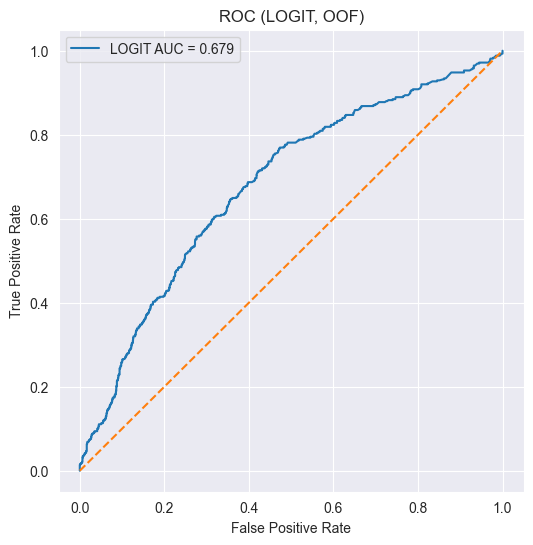


=== PROBIT summary ===
                          Probit Regression Results                           
Dep. Variable:                      y   No. Observations:                 2487
Model:                         Probit   Df Residuals:                     2466
Method:                           MLE   Df Model:                           20
Date:                Sun, 12 Oct 2025   Pseudo R-squ.:                 0.08644
Time:                        11:50:37   Log-Likelihood:                -1039.0
converged:                       True   LL-Null:                       -1137.3
Covariance Type:            nonrobust   LLR p-value:                 5.278e-31
                                                         coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------------------------
Intercept                                             -0.8904      0.355     -2.510      0.012      -1.586

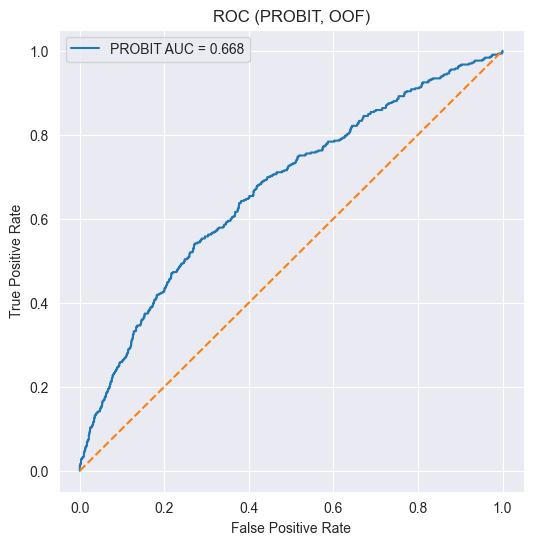


Top-20 OR (LOGIT, L2):
                                           feature       OR
                                      PhD_students 1.176589
                    C(teaching_position)[T.доцент] 1.156546
                                     courses_total 1.114810
                               C(faculty)[T.human] 1.099535
                                   thesis_bachelor 1.054316
                                      HSE_graduate 1.053207
                                    C(gender)[T.M] 1.034941
                                     thesis_master 1.025285
                                C(faculty)[T.math] 1.000000
     C(teaching_position)[T.старший преподаватель] 1.000000
                 C(teaching_position)[T.ассистент] 1.000000
C(teaching_position)[T.приглашенный преподаватель] 1.000000
             C(teaching_position)[T.преподаватель] 1.000000
                                       deg_has_phd 1.000000
                                     position_head 1.000000
                

In [34]:
# ===================== LOGIT → PROBIT по df (групп-валидация при наличии id) =====================
import numpy as np
import pandas as pd
import re, warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)

import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.model_selection import GroupKFold, StratifiedKFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, precision_recall_curve, roc_curve
)
from scipy.stats import chi2
import matplotlib.pyplot as plt

# ===== 0) ДАТА =====
df_main = df.copy()
df_main = df_main.rename(columns=lambda x: str(x).replace('.', '_'))
assert 'best_teacher' in df_main.columns, "Нужен целевой столбец 'best_teacher' (0/1)."
df_main['y'] = pd.to_numeric(df_main['best_teacher'], errors='coerce').fillna(0).astype(int)

# ===== 1) Утилиты =====
def collapse_rare_levels(s: pd.Series, min_count=20, other_label='Other'):
    vc = s.value_counts(dropna=False)
    rare = vc[vc < min_count].index
    return s.where(~s.isin(rare), other_label)

def bin_flag(col: pd.Series, pattern: str):
    return col.fillna("").astype(str).str.contains(pattern, flags=re.IGNORECASE, regex=True).astype(int)

def hosmer_lemeshow(y_true, y_prob, g=10):
    data = pd.DataFrame({'y': y_true, 'prob': y_prob})
    data['group'] = pd.qcut(data['prob'], g, duplicates='drop')
    obs = data.groupby('group', observed=False)['y'].agg(['sum','count'])
    obs['exp'] = data.groupby('group', observed=False)['prob'].sum()
    stat = (((obs['sum'] - obs['exp'])**2) / (obs['exp'] * (1 - obs['exp']/obs['count']))).sum()
    pval = 1 - chi2.cdf(stat, g-2)
    return float(stat), float(pval)

def eval_metrics(y_true, y_prob):
    prec, rec, thr = precision_recall_curve(y_true, y_prob)
    f1 = 2 * prec * rec / (prec + rec + 1e-10)
    best_idx = int(np.nanargmax(f1))
    thr_best = (thr[best_idx] if len(thr) else 0.5)
    y_pred = (y_prob >= thr_best).astype(int)
    return {
        'thr': float(thr_best),
        'F1': float(f1[best_idx]),
        'AUC': float(roc_auc_score(y_true, y_prob)),
        'ACC': float(accuracy_score(y_true, y_pred)),
        'PREC': float(precision_score(y_true, y_pred, zero_division=0)),
        'REC': float(recall_score(y_true, y_pred, zero_division=0)),
        'cm': confusion_matrix(y_true, y_pred)
    }

def print_cm(cm):
    tn, fp, fn, tp = cm.ravel()
    print(f"Confusion matrix:\n[[{tn:4d} {fp:4d}]\n [{fn:4d} {tp:4d}]]")

# ===== 2) Фичи (берём, если есть в df) =====
candidate_cat = ['gender','faculty','teaching_position','year']
candidate_bin = ['publications_english','HSE_graduate','position_head']
candidate_num = ['thesis_bachelor','thesis_master','PhD_students','PhD_finished','courses_total']

cat_cols = [c for c in candidate_cat if c in df_main.columns]
bin_cols = [c for c in candidate_bin if c in df_main.columns]
num_cols = [c for c in candidate_num if c in df_main.columns]

# degree → флаг (по желанию)
if 'degree' in df_main.columns:
    df_main['deg_has_phd'] = bin_flag(df_main['degree'], r'\bPhD\b|Doctor of Philosophy|доктор философии')
    bin_cols += ['deg_has_phd']

# чистка
for c in cat_cols:
    df_main[c] = collapse_rare_levels(df_main[c].astype(str), min_count=20).fillna('NA')
for c in num_cols:
    df_main[c] = pd.to_numeric(df_main[c], errors='coerce')
    med = df_main[c].median()
    df_main[c] = df_main[c].fillna(med if np.isfinite(med) else 0.0)
for c in bin_cols:
    df_main[c] = df_main[c].fillna(0).astype(int)

# формула
rhs = [f"C({c})" for c in cat_cols] + bin_cols + num_cols
assert len(rhs) > 0, "Не найдено ни одной фичи. Добавь хотя бы одну предикторную колонку."
formula = "y ~ " + " + ".join(rhs)
print("Formula:", formula)

# ===== 3) Валидация (GroupKFold по id, иначе StratifiedKFold) =====
use_groups = 'id' in df_main.columns
groups = df_main['id'].values if use_groups else None
if use_groups:
    splitter = GroupKFold(n_splits=5)
    split_iter = splitter.split(df_main, df_main['y'], groups=groups)
else:
    splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    split_iter = splitter.split(df_main, df_main['y'])

# ===== 4) LOGIT с L2 (подбор alpha) — ПЕРВЫМ =====
alphas = [0.1, 0.3, 1.0, 3.0, 10.0]
cv_results = []

for a in alphas:
    auc_scores = []
    for tr_idx, te_idx in (GroupKFold(n_splits=5).split(df_main, df_main['y'], groups=groups) if use_groups
    else StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(df_main, df_main['y'])):
        tr, te = df_main.iloc[tr_idx], df_main.iloc[te_idx]
        fit = smf.logit(formula=formula, data=tr).fit_regularized(
            method='l1', alpha=a, L1_wt=0.0, disp=False   # L2
        )
        y_prob = np.asarray(fit.predict(te))
        auc_scores.append(roc_auc_score(te['y'].values, y_prob))
    cv_results.append((a, float(np.mean(auc_scores)), float(np.std(auc_scores))))

best_alpha, best_auc, best_std = sorted(cv_results, key=lambda t: -t[1])[0]
print("\n=== LOGIT: CV (AUC, 5-fold) ===")
for a, m, s in cv_results:
    print(f"alpha={a:<4} | AUC={m:.3f} ± {s:.3f}")
print(f"\nBest alpha: {best_alpha} | CV AUC={best_auc:.3f} ± {best_std:.3f}")

# финальный логит
fit_logit = smf.logit(formula=formula, data=df_main).fit_regularized(
    method='l1', alpha=best_alpha, L1_wt=0.0, disp=False
)
print("\n=== LOGIT (L2) — коэффициенты ===")
print(fit_logit.params.sort_values(ascending=False).to_string())

# OOF для логита
oof_prob_logit = np.empty(len(df_main)); oof_prob_logit[:] = np.nan
for tr_idx, te_idx in (GroupKFold(n_splits=5).split(df_main, df_main['y'], groups=groups) if use_groups
else StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(df_main, df_main['y'])):
    tr, te = df_main.iloc[tr_idx], df_main.iloc[te_idx]
    f = smf.logit(formula=formula, data=tr).fit_regularized(method='l1', alpha=best_alpha, L1_wt=0.0, disp=False)
    oof_prob_logit[te_idx] = np.asarray(f.predict(te))

metrics_logit = eval_metrics(df_main['y'].values, oof_prob_logit)
hl_stat, hl_p = hosmer_lemeshow(df_main['y'].values, oof_prob_logit)
print("\n=== LOGIT OOF metrics ===")
print(f"AUC={metrics_logit['AUC']:.3f} | F1={metrics_logit['F1']:.3f} | Thr={metrics_logit['thr']:.3f} | "
      f"ACC={metrics_logit['ACC']:.3f} | PREC={metrics_logit['PREC']:.3f} | REC={metrics_logit['REC']:.3f}")
print_cm(metrics_logit['cm'])
print(f"Hosmer–Lemeshow: stat={hl_stat:.3f}, p={hl_p:.3f}")

# ROC для логита
fpr, tpr, _ = roc_curve(df_main['y'].values, oof_prob_logit)
plt.figure(figsize=(6,6))
plt.plot(fpr, tpr, label=f"LOGIT AUC = {metrics_logit['AUC']:.3f}")
plt.plot([0,1],[0,1],'--')
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC (LOGIT, OOF)"); plt.legend(); plt.show()

# ===== 5) PROBIT (следом, без регуляризации; при сложной модели урезай фичи) =====
try:
    fit_probit = smf.probit(formula=formula, data=df_main).fit(disp=False)
    print("\n=== PROBIT summary ===")
    print(fit_probit.summary())

    # OOF для probit
    oof_prob_probit = np.empty(len(df_main)); oof_prob_probit[:] = np.nan
    for tr_idx, te_idx in (GroupKFold(n_splits=5).split(df_main, df_main['y'], groups=groups) if use_groups
    else StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(df_main, df_main['y'])):
        tr, te = df_main.iloc[tr_idx], df_main.iloc[te_idx]
        f = smf.probit(formula=formula, data=tr).fit(disp=False)
        oof_prob_probit[te_idx] = np.asarray(f.predict(te))

    metrics_probit = eval_metrics(df_main['y'].values, oof_prob_probit)
    print("\n=== PROBIT OOF metrics ===")
    print(f"AUC={metrics_probit['AUC']:.3f} | F1={metrics_probit['F1']:.3f} | Thr={metrics_probit['thr']:.3f} | "
          f"ACC={metrics_probit['ACC']:.3f} | PREC={metrics_probit['PREC']:.3f} | REC={metrics_probit['REC']:.3f}")
    print_cm(metrics_probit['cm'])

    # ROC для пробита
    fpr2, tpr2, _ = roc_curve(df_main['y'].values, oof_prob_probit)
    plt.figure(figsize=(6,6))
    plt.plot(fpr2, tpr2, label=f"PROBIT AUC = {metrics_probit['AUC']:.3f}")
    plt.plot([0,1],[0,1],'--')
    plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
    plt.title("ROC (PROBIT, OOF)"); plt.legend(); plt.show()

except Exception as e:
    print("\n⚠️ PROBIT не сошёлся: ", repr(e))
    print("Сократи формулу (меньше категорий/фичей) или оставь LOGIT (L2) как основной.")

# ===== 6) OR для LOGIT =====
or_df = pd.DataFrame({
    'feature': fit_logit.params.index,
    'OR': np.exp(fit_logit.params.values)
}).sort_values('OR', ascending=False)
print("\nTop-20 OR (LOGIT, L2):")
print(or_df.head(20).to_string(index=False))


Formula: y ~ C(gender) + C(faculty) + C(teaching_position) + C(year) + publications_english + HSE_graduate + position_head + deg_has_phd + thesis_bachelor + thesis_master + PhD_students + PhD_finished + courses_total

=== CV AUC по alpha (LOGIT L2) ===
alpha=0.1  | AUC=0.670 ± 0.021
alpha=0.3  | AUC=0.670 ± 0.021
alpha=1.0  | AUC=0.672 ± 0.020
alpha=3.0  | AUC=0.675 ± 0.018
alpha=10.0 | AUC=0.680 ± 0.027
Best alpha = 10.0 | AUC=0.680 ± 0.027

=== LOGIT (OOF) ===
AUC=0.679 | F1=0.385 | Thr=0.188 | ACC=0.695 | PREC=0.294 | REC=0.558 | Brier=0.1345
Hosmer–Lemeshow: stat=32.872, p=0.000
Confusion matrix:
[[1492  570]
 [ 188  237]]

=== PROBIT (OOF) ===
AUC=0.668 | F1=0.378 | Thr=0.194 | ACC=0.696 | PREC=0.290 | REC=0.541 | Brier=0.1341
Hosmer–Lemeshow: stat=18.217, p=0.020
Confusion matrix:
[[1500  562]
 [ 195  230]]

=== Сравнение ===
corr(p_logit, p_probit) = 0.9126
ΔAUC (logit - probit)   = +0.0104
ΔBrier (logit - probit) = +0.00043

=== Модельные критерии (полный фит) ===
LOGIT:  McFad

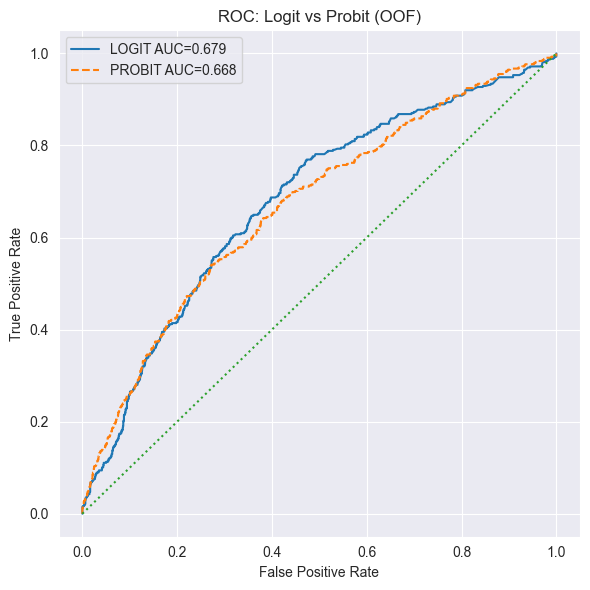

In [37]:
# ===================== LOGIT vs PROBIT на ~2400 (групп-валидация, L2, формулы, сравнение) =====================
import numpy as np
import pandas as pd
import re, warnings, os
warnings.filterwarnings("ignore", category=RuntimeWarning)

import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.model_selection import GroupKFold, KFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, precision_recall_curve, roc_curve
)
from scipy.stats import chi2
import matplotlib.pyplot as plt

# ===== 0) Вход =====
# Подставь свой датафрейм:
df_full = df.copy()  # <- твой df здесь

# Настрой: имена колонок
ID_COL = 'id'                    # если нет, поставь None
TARGET = 'best_teacher'          # бинарный 0/1
CATS   = ['gender','faculty','teaching_position','year']  # существующие в df
BINS   = ['publications_english','HSE_graduate','position_head']
NUMS   = ['thesis_bachelor','thesis_master','PhD_students','PhD_finished','courses_total']

# ===== 1) Утилиты =====
def collapse_rare_levels(s: pd.Series, min_count=20, other_label='Other'):
    vc = s.value_counts(dropna=False)
    rare = vc[vc < min_count].index
    return s.where(~s.isin(rare), other_label)

def bin_flag(col: pd.Series, pattern: str):
    return col.fillna("").astype(str).str.contains(pattern, flags=re.IGNORECASE, regex=True).astype(int)

def hosmer_lemeshow(y_true, y_prob, g=10):
    data = pd.DataFrame({'y': y_true, 'prob': y_prob})
    data['group'] = pd.qcut(data['prob'], g, duplicates='drop')
    obs = data.groupby('group', observed=False)['y'].agg(['sum','count'])
    obs['exp'] = data.groupby('group', observed=False)['prob'].sum()
    stat = (((obs['sum'] - obs['exp'])**2) / (obs['exp'] * (1 - obs['exp']/obs['count']))).sum()
    pval = 1 - chi2.cdf(stat, g-2)
    return float(stat), float(pval)

def brier_score(y_true, y_prob):
    y_true = np.asarray(y_true).astype(float)
    y_prob = np.asarray(y_prob).astype(float)
    return float(np.mean((y_true - y_prob)**2))

def eval_metrics(y_true, y_prob):
    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob).astype(float)
    # Порог по максимуму F1
    prec, rec, thr = precision_recall_curve(y_true, y_prob)
    f1 = 2 * prec * rec / (prec + rec + 1e-10)
    best_idx = int(np.nanargmax(f1))
    thr_best = (thr[best_idx] if len(thr) else 0.5)
    y_pred = (y_prob >= thr_best).astype(int)
    cm = confusion_matrix(y_true, y_pred)
    return {
        'thr': float(thr_best),
        'F1': float(f1[best_idx]),
        'AUC': float(roc_auc_score(y_true, y_prob)),
        'ACC': float(accuracy_score(y_true, y_pred)),
        'PREC': float(precision_score(y_true, y_pred, zero_division=0)),
        'REC': float(recall_score(y_true, y_pred, zero_division=0)),
        'Brier': brier_score(y_true, y_prob),
        'HL': hosmer_lemeshow(y_true, y_prob),
        'cm': cm
    }

def print_cm(cm):
    tn, fp, fn, tp = cm.ravel()
    print(f"Confusion matrix:\n[[{tn:4d} {fp:4d}]\n [{fn:4d} {tp:4d}]]")

# ===== 2) Подготовка =====
dfm = df_full.rename(columns=lambda x: str(x).replace('.', '_')).copy()
assert TARGET in dfm.columns, f"В df нет TARGET='{TARGET}'"
dfm['y'] = pd.to_numeric(dfm[TARGET], errors='coerce').fillna(0).astype(int)

cat_cols = [c for c in CATS if c in dfm.columns]
bin_cols = [c for c in BINS if c in dfm.columns]
num_cols = [c for c in NUMS if c in dfm.columns]

# Пример с degree → сделаем 1 флаг, чтобы не раздувать
if 'degree' in dfm.columns:
    dfm['deg_has_phd'] = bin_flag(dfm['degree'], r'\bPhD\b|Doctor of Philosophy|доктор философии')
    bin_cols = list(dict.fromkeys(bin_cols + ['deg_has_phd']))

# Чистка
for c in cat_cols:
    dfm[c] = collapse_rare_levels(dfm[c].astype(str), min_count=20).fillna('NA')
for c in num_cols:
    dfm[c] = pd.to_numeric(dfm[c], errors='coerce')
    med = dfm[c].median()
    dfm[c] = dfm[c].fillna(med if np.isfinite(med) else 0.0)
for c in bin_cols:
    dfm[c] = dfm[c].fillna(0).astype(int)

rhs = [f"C({c})" for c in cat_cols] + bin_cols + num_cols
formula = "y ~ " + " + ".join(rhs)
print("Formula:", formula)

# ===== 3) CV-сплит =====
if ID_COL and ID_COL in dfm.columns:
    groups = dfm[ID_COL].values
    splitter = GroupKFold(n_splits=5)
    split_iter = list(splitter.split(dfm, dfm['y'], groups=groups))
else:
    splitter = KFold(n_splits=5, shuffle=True, random_state=42)
    split_iter = list(splitter.split(dfm, dfm['y']))

# ===== 4) Логит с L2 — подбор alpha по AUC =====
alphas = [0.1, 0.3, 1.0, 3.0, 10.0]
cv_auc = []
for a in alphas:
    scores = []
    for tr_idx, te_idx in split_iter:
        tr, te = dfm.iloc[tr_idx], dfm.iloc[te_idx]
        fit = smf.logit(formula=formula, data=tr).fit_regularized(
            method='l1', alpha=a, L1_wt=0.0, disp=False
        )
        p = np.asarray(fit.predict(te))
        scores.append(roc_auc_score(te['y'].values, p))
    cv_auc.append((a, float(np.mean(scores)), float(np.std(scores))))
best_alpha, best_auc, best_std = sorted(cv_auc, key=lambda t: -t[1])[0]
print("\n=== CV AUC по alpha (LOGIT L2) ===")
for a, m, s in cv_auc:
    print(f"alpha={a:<4} | AUC={m:.3f} ± {s:.3f}")
print(f"Best alpha = {best_alpha} | AUC={best_auc:.3f} ± {best_std:.3f}")

# ===== 5) OOF предсказания для LOGIT и PROBIT =====
oof_logit = np.full(len(dfm), np.nan)
oof_probit = np.full(len(dfm), np.nan)

for tr_idx, te_idx in split_iter:
    tr, te = dfm.iloc[tr_idx], dfm.iloc[te_idx]
    # LOGIT L2
    fL = smf.logit(formula=formula, data=tr).fit_regularized(
        method='l1', alpha=best_alpha, L1_wt=0.0, disp=False
    )
    oof_logit[te_idx] = np.asarray(fL.predict(te))
    # PROBIT (без регуляризации; с твоими фичами при n~2400 обычно ок)
    fP = smf.probit(formula=formula, data=tr).fit(disp=False)
    oof_probit[te_idx] = np.asarray(fP.predict(te))

# Финальные модели на всей выборке (для коэффициентов, AIC/BIC)
fit_logit_full = smf.logit(formula=formula, data=dfm).fit_regularized(
    method='l1', alpha=best_alpha, L1_wt=0.0, disp=False
)
fit_probit_full = smf.probit(formula=formula, data=dfm).fit(disp=False)

# ===== 6) Метрики и сравнение =====
mL = eval_metrics(dfm['y'].values, oof_logit)
mP = eval_metrics(dfm['y'].values, oof_probit)

corr = float(np.corrcoef(oof_logit, oof_probit)[0,1])
delta_auc = mL['AUC'] - mP['AUC']
delta_brier = mL['Brier'] - mP['Brier']

print("\n=== LOGIT (OOF) ===")
print(f"AUC={mL['AUC']:.3f} | F1={mL['F1']:.3f} | Thr={mL['thr']:.3f} | ACC={mL['ACC']:.3f} | "
      f"PREC={mL['PREC']:.3f} | REC={mL['REC']:.3f} | Brier={mL['Brier']:.4f}")
print(f"Hosmer–Lemeshow: stat={mL['HL'][0]:.3f}, p={mL['HL'][1]:.3f}")
print_cm(mL['cm'])

print("\n=== PROBIT (OOF) ===")
print(f"AUC={mP['AUC']:.3f} | F1={mP['F1']:.3f} | Thr={mP['thr']:.3f} | ACC={mP['ACC']:.3f} | "
      f"PREC={mP['PREC']:.3f} | REC={mP['REC']:.3f} | Brier={mP['Brier']:.4f}")
print(f"Hosmer–Lemeshow: stat={mP['HL'][0]:.3f}, p={mP['HL'][1]:.3f}")
print_cm(mP['cm'])

print("\n=== Сравнение ===")
print(f"corr(p_logit, p_probit) = {corr:.4f}")
print(f"ΔAUC (logit - probit)   = {delta_auc:+.4f}")
print(f"ΔBrier (logit - probit) = {delta_brier:+.5f}")

# Псевдо-R2 МакФаддена, AIC/BIC на полном фите
def mcfadden_r2(fit):
    llf = fit.llf
    llnull = fit.llnull if hasattr(fit, 'llnull') else None
    if llnull is None:
        # оценим llnull логитом с константой
        y = fit.model.endog
        X = np.ones((len(y),1))
        m0 = sm.Logit(y, X).fit(disp=False)
        llnull = m0.llf
    return 1 - (llf / llnull)

print("\n=== Модельные критерии (полный фит) ===")
print(f"LOGIT:  McFadden R2={mcfadden_r2(fit_logit_full):.3f} | AIC≈{fit_logit_full.aic:.1f} | BIC≈{fit_logit_full.bic:.1f}")
print(f"PROBIT: McFadden R2={mcfadden_r2(fit_probit_full):.3f} | AIC≈{fit_probit_full.aic:.1f} | BIC≈{fit_probit_full.bic:.1f}")

# ===== 7) Коэффициенты/OR =====
print("\n=== LOGIT (L2) — коэффициенты (top ±) ===")
print(fit_logit_full.params.sort_values(ascending=False).head(15).to_string())
print(fit_logit_full.params.sort_values(ascending=True).head(15).to_string())

or_df = pd.DataFrame({'feature': fit_logit_full.params.index,
                      'OR': np.exp(fit_logit_full.params.values)}).sort_values('OR', ascending=False)
print("\nTop-15 OR (LOGIT, L2):")
print(or_df.head(15).to_string(index=False))

print("\n=== PROBIT — коэффициенты (масштаб другой, сравниваем только знаки) ===")
print(fit_probit_full.params.sort_values(ascending=False).head(15).to_string())
print(fit_probit_full.params.sort_values(ascending=True).head(15).to_string())

# ===== 8) ROC-графики =====
fprL, tprL, _ = roc_curve(dfm['y'].values, oof_logit)
fprP, tprP, _ = roc_curve(dfm['y'].values, oof_probit)
plt.figure(figsize=(6,6))
plt.plot(fprL, tprL, label=f"LOGIT AUC={mL['AUC']:.3f}")
plt.plot(fprP, tprP, label=f"PROBIT AUC={mP['AUC']:.3f}", linestyle='--')
plt.plot([0,1],[0,1],':')
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC: Logit vs Probit (OOF)")
plt.legend(); plt.tight_layout(); plt.show()


Formula (no L2): y ~ C(gender) + C(faculty) + C(teaching_position) + C(year) + publications_english + HSE_graduate + position_head + deg_has_phd + thesis_bachelor + thesis_master + PhD_students + PhD_finished + courses_total

=== OOF SUMMARY (Logit, MLE, no L2) ===
Folds (AUC, AP, +rate): 1: AUC=0.694, AP=0.318, +rate=0.165; 2: AUC=0.695, AP=0.395, +rate=0.179; 3: AUC=0.653, AP=0.253, +rate=0.167; 4: AUC=0.645, AP=0.296, +rate=0.185; 5: AUC=0.663, AP=0.323, +rate=0.160
OOF AUC=0.668 | OOF AP=0.309 | Thr(F1)=0.196 | ACC=0.704 | PREC=0.293 | REC=0.518 | Brier=0.1341
Confusion matrix:
 [[1532  530]
 [ 205  220]]
Hosmer–Lemeshow: stat=13.965, p=0.083


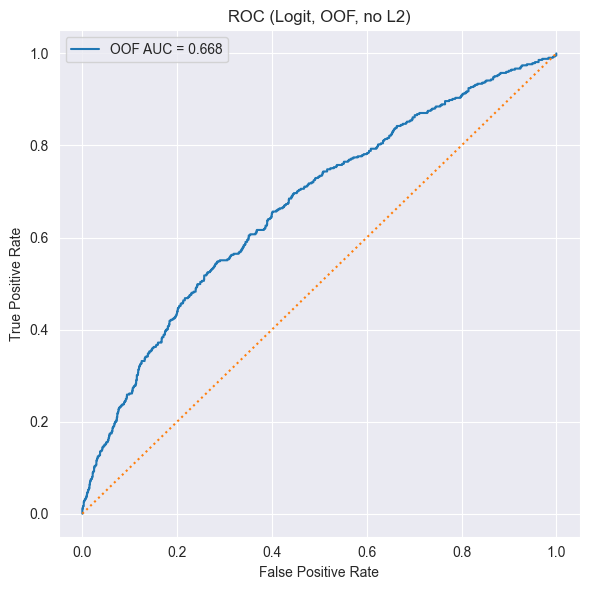

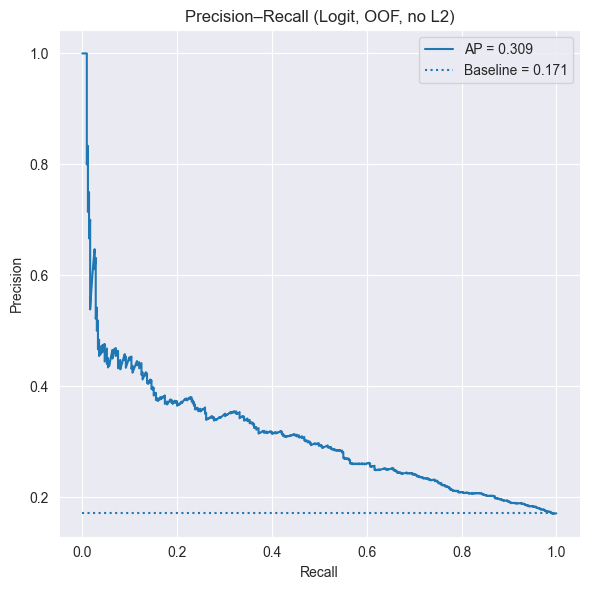

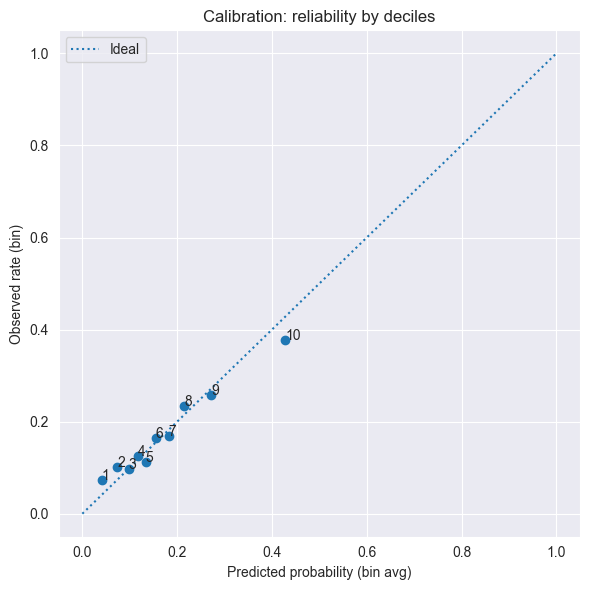


=== LOGIT (MLE, no L2) — TOP-15 по |β| (с p-value, робастные SE) ===
                                              term    beta     OR      p     se       z  ci_low  ci_high
C(teaching_position)[T.приглашенный преподаватель] -2.6287 0.0722 0.0067 0.9702 -2.7093 -4.5304  -0.7270
                 C(teaching_position)[T.ассистент] -2.1017 0.1222 0.0103 0.8196 -2.5642 -3.7082  -0.4952
                 C(teaching_position)[T.профессор] -1.5354 0.2154 0.0195 0.6573 -2.3360 -2.8237  -0.2471
             C(teaching_position)[T.преподаватель] -1.2138 0.2971 0.0749 0.6816 -1.7808 -2.5498   0.1222
     C(teaching_position)[T.старший преподаватель] -1.1902 0.3042 0.0637 0.6420 -1.8540 -2.4485   0.0681
                    C(teaching_position)[T.доцент] -0.8688 0.4195 0.1658 0.6269 -1.3858 -2.0975   0.3599
                               C(faculty)[T.human]  0.4727 1.6044 0.0147 0.1937  2.4406  0.0931   0.8524
                                      HSE_graduate  0.3731 1.4523 0.0290 0.1709  2.1833  0

In [45]:
# ================= LOGIT (MLE, БЕЗ L2) — полный преданализ: OOF, ROC/PR, калибровка, HL, ТОП-15 β и p =================
import numpy as np
import pandas as pd
import warnings, re
warnings.filterwarnings("ignore", category=RuntimeWarning)

import matplotlib.pyplot as plt

import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy.stats import chi2, norm

from sklearn.model_selection import GroupKFold, KFold
from sklearn.metrics import (
    roc_auc_score, roc_curve, average_precision_score,
    precision_recall_curve, accuracy_score, precision_score, recall_score,
    confusion_matrix
)

# ================= НАСТРОЙКИ =================
TARGET = 'best_teacher'     # бинарный таргет 0/1
ID_COL = 'id'               # идентификатор человека; если нет — поставь None
MIN_CAT_COUNT = 20          # минимум наблюдений в категории; реже -> "Other"
N_SPLITS = 5                # число фолдов GroupKFold/KFold
TOP_K = 15                  # сколько факторов выводить

# ================= ПРОВЕРКА ВХОДА =================
assert 'df' in globals(), "Положи свой DataFrame в переменную df"
dfm = df.copy().rename(columns=lambda x: str(x).replace('.', '_'))
assert TARGET in dfm.columns, f"Нет столбца TARGET='{TARGET}'"

# ================= ПОДГОТОВКА ФИЧ =================
dfm['y'] = pd.to_numeric(dfm[TARGET], errors='coerce').fillna(0).astype(int)

CATS = [c for c in ['gender','faculty','teaching_position','year'] if c in dfm.columns]
BINS = [c for c in ['publications_english','HSE_graduate','position_head'] if c in dfm.columns]
NUMS = [c for c in ['thesis_bachelor','thesis_master','PhD_students','PhD_finished','courses_total'] if c in dfm.columns]

# degree -> аккуратный флаг
if 'degree' in dfm.columns:
    dfm['deg_has_phd'] = (dfm['degree'].fillna('')
                          .astype(str)
                          .str.contains(r'\bPhD\b|Doctor of Philosophy|доктор философии', flags=re.IGNORECASE, regex=True)
                          .astype(int))
    if 'deg_has_phd' not in BINS:
        BINS.append('deg_has_phd')

def collapse_rare_levels(s: pd.Series, min_count=20, other_label='Other'):
    vc = s.astype(str).value_counts(dropna=False)
    rare = vc[vc < min_count].index
    return s.astype(str).where(~s.astype(str).isin(rare), other_label)

for c in CATS:
    dfm[c] = collapse_rare_levels(dfm[c], MIN_CAT_COUNT).fillna('NA')
for c in NUMS:
    dfm[c] = pd.to_numeric(dfm[c], errors='coerce')
    med = dfm[c].median()
    dfm[c] = dfm[c].fillna(med if np.isfinite(med) else 0.0)
for c in BINS:
    dfm[c] = dfm[c].fillna(0).astype(int)

rhs = [f"C({c})" for c in CATS] + BINS + NUMS
formula = "y ~ " + " + ".join(rhs)
print("Formula (no L2):", formula)

# ================= СПЛИТЫ (GroupKFold, если есть id) =================
if ID_COL and ID_COL in dfm.columns:
    groups = dfm[ID_COL].values
    splitter = GroupKFold(n_splits=N_SPLITS)
    splits = list(splitter.split(dfm, dfm['y'], groups=groups))
else:
    splitter = KFold(n_splits=N_SPLITS, shuffle=True, random_state=42)
    splits = list(splitter.split(dfm, dfm['y']))

# ================= OOF-ПРОГОН (MLE, без L2) =================
oof_prob = np.full(len(dfm), np.nan, dtype=float)
fold_stats = []

def _fit_logit_mle(data, formula, cov_type, cov_kw):
    # Иногда Ньютона мало — добавим чуть итераций
    return smf.logit(formula=formula, data=data).fit(disp=False, cov_type=cov_type, cov_kwds=cov_kw, maxiter=200)

for fold, (tr_idx, te_idx) in enumerate(splits, 1):
    tr, te = dfm.iloc[tr_idx], dfm.iloc[te_idx]

    # робастные ошибки: кластер по id, если есть
    if ID_COL and ID_COL in dfm.columns:
        cov_type, cov_kw = 'cluster', {'groups': tr[ID_COL].values}
    else:
        cov_type, cov_kw = 'HC1', None

    # основной фит; если не сойдется — fallback на компактную формулу
    try:
        fit = _fit_logit_mle(tr, formula, cov_type, cov_kw)
    except Exception as e:
        mini_rhs = [r for r in [
            "C(gender)", "C(faculty)", "C(teaching_position)", "C(year)",
            "HSE_graduate", "PhD_students", "courses_total", "thesis_bachelor", "PhD_finished"
        ] if (r.startswith("C(") and r[2:-1] in tr.columns) or (r in tr.columns)]
        formula_fallback = "y ~ " + " + ".join(mini_rhs)
        print(f"⚠️ Fold {fold}: full formula struggled. Fallback to:", formula_fallback)
        fit = _fit_logit_mle(tr, formula_fallback, cov_type, cov_kw)

    p = np.asarray(fit.predict(te))
    oof_prob[te_idx] = p

    auc = roc_auc_score(te['y'].values, p)
    ap = average_precision_score(te['y'].values, p)
    fold_stats.append((fold, float(auc), float(ap), float(te['y'].mean())))

# ================= МЕТРИКИ OOF =================
y_true = dfm['y'].values

def hosmer_lemeshow(y_true, y_prob, g=10):
    data = pd.DataFrame({'y': y_true, 'prob': y_prob})
    data['group'] = pd.qcut(data['prob'], g, duplicates='drop')
    obs = data.groupby('group', observed=False)['y'].agg(['sum','count'])
    obs['exp'] = data.groupby('group', observed=False)['prob'].sum()
    stat = (((obs['sum'] - obs['exp'])**2) / (obs['exp'] * (1 - obs['exp']/obs['count']))).sum()
    pval = 1 - chi2.cdf(stat, g-2)
    return float(stat), float(pval), obs.reset_index()

auc_oof = roc_auc_score(y_true, oof_prob)
ap_oof  = average_precision_score(y_true, oof_prob)

prec, rec, thr = precision_recall_curve(y_true, oof_prob)
f1 = 2 * prec * rec / (prec + rec + 1e-10)
best_idx = int(np.nanargmax(f1))
thr_best = float(thr[best_idx]) if len(thr) else 0.5
y_pred = (oof_prob >= thr_best).astype(int)

acc = accuracy_score(y_true, y_pred)
pre = precision_score(y_true, y_pred, zero_division=0)
recall = recall_score(y_true, y_pred, zero_division=0)
cm = confusion_matrix(y_true, y_pred)
hl_stat, hl_p, hl_table = hosmer_lemeshow(y_true, oof_prob, g=10)
brier = float(np.mean((y_true - oof_prob)**2))

print("\n=== OOF SUMMARY (Logit, MLE, no L2) ===")
print("Folds (AUC, AP, +rate):", "; ".join([f"{i}: AUC={a:.3f}, AP={ap:.3f}, +rate={r:.3f}" for i,a,ap,r in fold_stats]))
print(f"OOF AUC={auc_oof:.3f} | OOF AP={ap_oof:.3f} | Thr(F1)={thr_best:.3f} | "
      f"ACC={acc:.3f} | PREC={pre:.3f} | REC={recall:.3f} | Brier={brier:.4f}")
print("Confusion matrix:\n", cm)
print(f"Hosmer–Lemeshow: stat={hl_stat:.3f}, p={hl_p:.3f}")

# ================= ГРАФИКИ: ROC, PR, КАЛИБРОВКА =================
# ROC
fpr, tpr, _ = roc_curve(y_true, oof_prob)
plt.figure(figsize=(6,6))
plt.plot(fpr, tpr, label=f"OOF AUC = {auc_oof:.3f}")
plt.plot([0,1],[0,1], linestyle=':')
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC (Logit, OOF, no L2)"); plt.legend(); plt.tight_layout(); plt.show()

# PR
pr_p, pr_r, _ = precision_recall_curve(y_true, oof_prob)
ap = average_precision_score(y_true, oof_prob)
plt.figure(figsize=(6,6))
plt.plot(pr_r, pr_p, label=f"AP = {ap:.3f}")
plt.hlines(y_true.mean(), 0, 1, linestyles=':', label=f"Baseline = {y_true.mean():.3f}")
plt.xlabel("Recall"); plt.ylabel("Precision")
plt.title("Precision–Recall (Logit, OOF, no L2)"); plt.legend(); plt.tight_layout(); plt.show()

# Calibration (reliability) plot: по децилям из HL
calib = hl_table.copy()
calib['obs_rate'] = calib['sum'] / calib['count']
calib['avg_prob'] = calib['exp'] / calib['count']
plt.figure(figsize=(6,6))
plt.plot([0,1],[0,1], linestyle=':', label='Ideal')
plt.scatter(calib['avg_prob'], calib['obs_rate'])
for i,(xp,yp,n) in enumerate(zip(calib['avg_prob'], calib['obs_rate'], calib['count'])):
    plt.annotate(str(i+1), (xp, yp))
plt.xlabel("Predicted probability (bin avg)"); plt.ylabel("Observed rate (bin)")
plt.title("Calibration: reliability by deciles"); plt.legend(); plt.tight_layout(); plt.show()

# ================= ПОЛНЫЙ ФИТ — β, p, OR, ДИ =================
if ID_COL and ID_COL in dfm.columns:
    cov_type, cov_kw = 'cluster', {'groups': dfm[ID_COL].values}
else:
    cov_type, cov_kw = 'HC1', None

# основной полный фит; при проблемах — мини-формула
try:
    fit_full = smf.logit(formula=formula, data=dfm).fit(disp=False, cov_type=cov_type, cov_kwds=cov_kw, maxiter=200)
except Exception as e:
    mini_rhs = [r for r in [
        "C(gender)", "C(faculty)", "C(teaching_position)", "C(year)",
        "HSE_graduate", "PhD_students", "courses_total", "thesis_bachelor", "PhD_finished"
    ] if (r.startswith("C(") and r[2:-1] in dfm.columns) or (r in dfm.columns)]
    formula = "y ~ " + " + ".join(mini_rhs)
    print("⚠️ Full model struggled. Fallback to mini formula:", formula)
    fit_full = smf.logit(formula=formula, data=dfm).fit(disp=False, cov_type=cov_type, cov_kwds=cov_kw, maxiter=200)

# аккуратно к Series → далее к numpy
P   = pd.Series(fit_full.params, index=fit_full.params.index)
SE  = pd.Series(fit_full.bse,    index=fit_full.params.index)
z   = P / SE
pval= pd.Series(2 * norm.sf(np.abs(z)), index=P.index)
OR  = np.exp(P)
ci_lo = P - 1.96 * SE
ci_hi = P + 1.96 * SE

coef_tbl = (pd.DataFrame({
    'term':   P.index,
    'beta':   P.to_numpy(),
    'abs_beta': np.abs(P.to_numpy()),
    'OR':     OR.to_numpy(),
    'se':     SE.to_numpy(),
    'z':      z.to_numpy(),
    'p':      pval.to_numpy(),
    'ci_low': ci_lo.to_numpy(),
    'ci_high':ci_hi.to_numpy(),
})
            .query("term != 'Intercept'")
            .reset_index(drop=True))

# ТОП-15 по |β|
top_by_abs = (coef_tbl.sort_values('abs_beta', ascending=False)
              .head(TOP_K)
              .reset_index(drop=True))
# ТОП-15 по p-value
top_by_p   = (coef_tbl.sort_values('p', ascending=True)
              .head(TOP_K)
              .reset_index(drop=True))

pd.set_option('display.float_format', lambda x: f"{x:0.4f}")
print(f"\n=== LOGIT (MLE, no L2) — TOP-{TOP_K} по |β| (с p-value, робастные SE) ===")
print(top_by_abs[['term','beta','OR','p','se','z','ci_low','ci_high']].to_string(index=False))

print(f"\n=== LOGIT (MLE, no L2) — TOP-{TOP_K} по значимости (p-value) ===")
print(top_by_p[['term','beta','OR','p','se','z','ci_low','ci_high']].to_string(index=False))


In [46]:
# === LOGIT (MLE, no L2) — Top-K по значимости (robust p, cluster by id) ===
import numpy as np, pandas as pd, warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)
import statsmodels.formula.api as smf
from scipy.stats import norm

# Настройки
TARGET = 'best_teacher'
ID_COL = 'id'
TOP_K = 10
MIN_CAT_COUNT = 20

# Подготовка
dfm = df.copy().rename(columns=lambda x: str(x).replace('.', '_'))
dfm['y'] = pd.to_numeric(dfm[TARGET], errors='coerce').fillna(0).astype(int)

CATS = [c for c in ['gender','faculty','teaching_position','year'] if c in dfm.columns]
BINS = [c for c in ['publications_english','HSE_graduate','position_head'] if c in dfm.columns]
NUMS = [c for c in ['thesis_bachelor','thesis_master','PhD_students','PhD_finished','courses_total'] if c in dfm.columns]

if 'degree' in dfm.columns:
    dfm['deg_has_phd'] = (dfm['degree'].fillna('')
                          .astype(str)
                          .str.contains(r'\bPhD\b|Doctor of Philosophy|доктор философии', case=False, regex=True)
                          .astype(int))
    if 'deg_has_phd' not in BINS: BINS.append('deg_has_phd')

def collapse_rare_levels(s: pd.Series, min_count=20, other_label='Other'):
    vc = s.astype(str).value_counts(dropna=False)
    rare = vc[vc < min_count].index
    return s.astype(str).where(~s.astype(str).isin(rare), other_label)

for c in CATS:
    dfm[c] = collapse_rare_levels(dfm[c], MIN_CAT_COUNT).fillna('NA')
for c in NUMS:
    dfm[c] = pd.to_numeric(dfm[c], errors='coerce').fillna(dfm[c].median())

for c in BINS:
    dfm[c] = dfm[c].fillna(0).astype(int)

rhs = [f"C({c})" for c in CATS] + BINS + NUMS
formula = "y ~ " + " + ".join(rhs)
print("Formula (no L2):", formula)

# Фит без регуляризации + робастные SE (cluster по id, иначе HC1)
if ID_COL in dfm.columns:
    fit = smf.logit(formula=formula, data=dfm).fit(disp=False, cov_type='cluster',
                                                   cov_kwds={'groups': dfm[ID_COL].values}, maxiter=200)
else:
    fit = smf.logit(formula=formula, data=dfm).fit(disp=False, cov_type='HC1', maxiter=200)

# Коэффициенты, p-value, OR, ДИ
P   = pd.Series(fit.params, index=fit.params.index)
SE  = pd.Series(fit.bse,    index=fit.params.index)
z   = P / SE
pvl = pd.Series(2 * norm.sf(np.abs(z)), index=P.index)
OR  = np.exp(P)
ci_lo = P - 1.96 * SE
ci_hi = P + 1.96 * SE

coef_tbl = (pd.DataFrame({
    'term': P.index, 'beta': P.to_numpy(), 'OR': OR.to_numpy(),
    'p': pvl.to_numpy(), 'se': SE.to_numpy(), 'z': z.to_numpy(),
    'ci_low': ci_lo.to_numpy(), 'ci_high': ci_hi.to_numpy()
})
            .query("term != 'Intercept'")
            .sort_values('p', ascending=True)
            .head(TOP_K)
            .reset_index(drop=True))

pd.set_option('display.float_format', lambda x: f"{x:0.4f}")
print("\n=== LOGIT (MLE, no L2) — Top-{0} по значимости ===".format(TOP_K))
print(coef_tbl[['term','beta','OR','p','ci_low','ci_high']].to_string(index=False))


Formula (no L2): y ~ C(gender) + C(faculty) + C(teaching_position) + C(year) + publications_english + HSE_graduate + position_head + deg_has_phd + thesis_bachelor + thesis_master + PhD_students + PhD_finished + courses_total

=== LOGIT (MLE, no L2) — Top-10 по значимости ===
                                              term    beta     OR      p  ci_low  ci_high
                                     courses_total  0.1057 1.1115 0.0000  0.0693   0.1421
C(teaching_position)[T.приглашенный преподаватель] -2.6287 0.0722 0.0067 -4.5304  -0.7270
                 C(teaching_position)[T.ассистент] -2.1017 0.1222 0.0103 -3.7082  -0.4952
                               C(faculty)[T.human]  0.4727 1.6044 0.0147  0.0931   0.8524
                                 C(year)[T.y24_25] -0.2914 0.7472 0.0152 -0.5267  -0.0560
                                      PhD_students  0.2028 1.2248 0.0192  0.0331   0.3725
                 C(teaching_position)[T.профессор] -1.5354 0.2154 0.0195 -2.8237  -0.2471
    

In [50]:
# === LOGIT (MLE, no L2) — Top-K по значимости (robust p, cluster by id) ===
import numpy as np, pandas as pd, warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)
import statsmodels.formula.api as smf
from scipy.stats import norm

# Настройки
TARGET = 'best_teacher'
ID_COL = 'id'
TOP_K = 15
MIN_CAT_COUNT = 20

# Подготовка
dfm = df.copy().rename(columns=lambda x: str(x).replace('.', '_'))
dfm['y'] = pd.to_numeric(dfm[TARGET], errors='coerce').fillna(0).astype(int)

CATS = [c for c in ['gender','faculty','teaching_position','year'] if c in dfm.columns]
BINS = [c for c in ['publications_english','HSE_graduate','position_head'] if c in dfm.columns]
NUMS = [c for c in ['thesis_bachelor','thesis_master','PhD_students','PhD_finished','courses_total'] if c in dfm.columns]

if 'degree' in dfm.columns:
    dfm['deg_has_phd'] = (dfm['degree'].fillna('')
                          .astype(str)
                          .str.contains(r'\bPhD\b|Doctor of Philosophy|доктор философии', case=False, regex=True)
                          .astype(int))
    if 'deg_has_phd' not in BINS: BINS.append('deg_has_phd')

def collapse_rare_levels(s: pd.Series, min_count=20, other_label='Other'):
    vc = s.astype(str).value_counts(dropna=False)
    rare = vc[vc < min_count].index
    return s.astype(str).where(~s.astype(str).isin(rare), other_label)

for c in CATS:
    dfm[c] = collapse_rare_levels(dfm[c], MIN_CAT_COUNT).fillna('NA')
for c in NUMS:
    dfm[c] = pd.to_numeric(dfm[c], errors='coerce').fillna(dfm[c].median())

for c in BINS:
    dfm[c] = dfm[c].fillna(0).astype(int)

rhs = [f"C({c})" for c in CATS] + BINS + NUMS
formula = "y ~ " + " + ".join(rhs)
print("Formula (no L2):", formula)

# Фит без регуляризации + робастные SE (cluster по id, иначе HC1)
if ID_COL in dfm.columns:
    fit = smf.logit(formula=formula, data=dfm).fit(disp=False, cov_type='cluster',
                                                   cov_kwds={'groups': dfm[ID_COL].values}, maxiter=200)
else:
    fit = smf.logit(formula=formula, data=dfm).fit(disp=False, cov_type='HC1', maxiter=200)

# Коэффициенты, p-value, OR, ДИ
P   = pd.Series(fit.params, index=fit.params.index)
SE  = pd.Series(fit.bse,    index=fit.params.index)
z   = P / SE
pvl = pd.Series(2 * norm.sf(np.abs(z)), index=P.index)
OR  = np.exp(P)
ci_lo = P - 1.96 * SE
ci_hi = P + 1.96 * SE

coef_tbl = (pd.DataFrame({
    'term': P.index, 'beta': P.to_numpy(), 'OR': OR.to_numpy(),
    'p': pvl.to_numpy(), 'se': SE.to_numpy(), 'z': z.to_numpy(),
    'ci_low': ci_lo.to_numpy(), 'ci_high': ci_hi.to_numpy()
})
            .query("term != 'Intercept'")
            .sort_values('p', ascending=True)
            .head(TOP_K)
            .reset_index(drop=True))

pd.set_option('display.float_format', lambda x: f"{x:0.4f}")
print("\n=== LOGIT (MLE, no L2) — Top-{0} по значимости ===".format(TOP_K))
print(coef_tbl[['term','beta','OR','p','ci_low','ci_high']].to_string(index=False))

Formula (no L2): y ~ C(gender) + C(faculty) + C(teaching_position) + C(year) + publications_english + HSE_graduate + position_head + deg_has_phd + thesis_bachelor + thesis_master + PhD_students + PhD_finished + courses_total

=== LOGIT (MLE, no L2) — Top-15 по значимости ===
                                              term    beta     OR      p  ci_low  ci_high
                                     courses_total  0.1057 1.1115 0.0000  0.0693   0.1421
C(teaching_position)[T.приглашенный преподаватель] -2.6287 0.0722 0.0067 -4.5304  -0.7270
                 C(teaching_position)[T.ассистент] -2.1017 0.1222 0.0103 -3.7082  -0.4952
                               C(faculty)[T.human]  0.4727 1.6044 0.0147  0.0931   0.8524
                                 C(year)[T.y24_25] -0.2914 0.7472 0.0152 -0.5267  -0.0560
                                      PhD_students  0.2028 1.2248 0.0192  0.0331   0.3725
                 C(teaching_position)[T.профессор] -1.5354 0.2154 0.0195 -2.8237  -0.2471
    

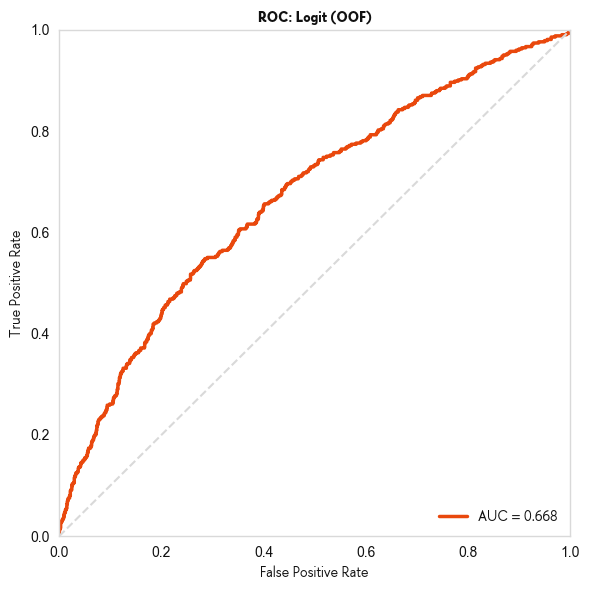

In [55]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score
import os
from matplotlib.font_manager import FontProperties, fontManager

# === фирменные цвета ===
ORANGE = "#e9480d"
BLACK  = "#111111"
GRAY_BORDER = "#D9D9D9"

# === HSE Sans (подставь свой путь при необходимости) ===
FONT_DIR = r"C:\Users\coldn\Downloads\HSE Sans"
def _resolve_font(*names):
    for name in names:
        path = os.path.join(FONT_DIR, name)
        if os.path.exists(path):
            return path
    return None  # мягкий фоллбэк

regular_font_path = _resolve_font("HSESans-Regular.otf", "HSESans-Regular.ttf")
bold_font_path    = _resolve_font("HSESans-Bold.otf",    "HSESans-Bold.ttf")
if regular_font_path: fontManager.addfont(regular_font_path)
if bold_font_path:    fontManager.addfont(bold_font_path)
REG = FontProperties(fname=regular_font_path) if regular_font_path else None
BOLD = FontProperties(fname=bold_font_path)   if bold_font_path else None

def plot_roc_hse(y_true, y_prob, title="ROC (Logit, OOF, no L2)"):
    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob).astype(float)
    auc = roc_auc_score(y_true, y_prob)
    fpr, tpr, _ = roc_curve(y_true, y_prob)

    fig, ax = plt.subplots(figsize=(6,6), facecolor="white")
    ax.set_facecolor("white")

    ax.plot(fpr, tpr, linewidth=2.5, color=ORANGE,
            label=f"AUC = {auc:.3f}")
    ax.plot([0,1],[0,1], linestyle="--", linewidth=1.5, color=GRAY_BORDER)

    # Оси/сетка/рамка
    ax.set_xlim(0,1); ax.set_ylim(0,1)
    ax.set_xlabel("False Positive Rate", color=BLACK, fontproperties=REG)
    ax.set_ylabel("True Positive Rate",  color=BLACK, fontproperties=REG)
    ax.set_title(title, color=BLACK, fontproperties=BOLD if BOLD else None)

    for spine in ax.spines.values():
        spine.set_color(GRAY_BORDER); spine.set_linewidth(1.0)
    ax.tick_params(colors=BLACK)
    ax.grid(False)
    leg = ax.legend(frameon=False, loc="lower right", prop=REG)
    for text in leg.get_texts():
        text.set_color(BLACK)

    plt.tight_layout()
    plt.savefig("ROC_auc.png")
    plt.show()
    return auc

# Пример вызова:
auc_val = plot_roc_hse(dfm['y'].values, oof_prob, title="ROC: Logit (OOF)")


In [12]:
def plot_best_by(
        df=None,
        x=None,                      # категориальный столбец по оси X
        y=None,                      # числовой столбец; если None — распределение x
        agg="mean",                  # "mean"|"median"|"sum"|"count" или callable
        title=None,
        filename=None,
        show_trend=True,
        sort_by="index",             # "index"|"value"|"count"
        ascending=True,
        rotation=20,
        nan_policy="drop",           # для y: "drop"|"zero"
        nan_category="drop",         # для x: "drop" или "keep" (=> категория "NaN")
        ylim=None,
        show_count=True,
        # === Новое ===
        as_percent="auto",           # True|False|"auto" — доли в % для бинарного y; для распределений — см. normalize
        normalize=None,              # None|"percent"|"fraction" для распределений (y=None)
        color_bar="#e9480d",         # строка или список цветов для столбиков
        color_trend="#242424",       # строка или список цветов для линии(й)
        xlabel=None,
        ylabel=None,
        orientation="vertikal",      # "vertical"|"horizontal"
        wrap_width=18,               # авто-перенос подписей категорий (символов в строке)
        log_axis="у",               # None|"x"|"y" — лог-масштаб
        facet_by=None,               # столбец для мини-фасетов (категории)
        facet_cols=3,                # число колонок фасет-сетки
        facet_order=None,            # явный порядок уровней facet_by
        facet_limit=None,            # максимум фасетов (для аккуратности)
        sharey=True                  # делиться осью Y между фасетами
):
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    import matplotlib.patheffects as path_effects
    import textwrap, os, math
    from matplotlib.font_manager import FontProperties, fontManager
    from matplotlib.ticker import FuncFormatter

    # ==== Шрифт HSE Sans ====
    FONT_DIR = r"C:\Users\coldn\Downloads\HSE Sans"

    def _resolve_font(*names):
        for name in names:
            path = os.path.join(FONT_DIR, name)
            if os.path.exists(path):
                return path
        raise FileNotFoundError("Не найден файл HSE Sans. Проверь FONT_DIR.")

    regular_font_path = _resolve_font("HSESans-Regular.otf", "HSESans-Regular.ttf")
    try:
        fontManager.addfont(regular_font_path)
    except Exception:
        pass

    font_prop_small  = FontProperties(fname=regular_font_path, size=12)
    font_prop_base   = FontProperties(fname=regular_font_path, size=14)
    font_prop_large  = FontProperties(fname=regular_font_path, size=16)
    font_prop_title  = FontProperties(fname=regular_font_path, size=20)

    ACCENT_GRAY  = "#E9E9E9"

    # ---- проверки ----
    if df is None or x is None:
        raise ValueError("Передай df и x.")
    if x not in df.columns:
        raise ValueError(f"Столбец x='{x}' не найден в df.")
    if (y is not None) and (y not in df.columns):
        raise ValueError(f"Столбец y='{y}' не найден в df.")
    if facet_by is not None and facet_by not in df.columns:
        raise ValueError(f"Столбец facet_by='{facet_by}' не найден в df.")

    # ---- палитры ----
    def _as_cycle(c):
        return (c if isinstance(c, (list, tuple, np.ndarray)) else [c])

    bar_cycle   = _as_cycle(color_bar)
    trend_cycle = _as_cycle(color_trend)

    # ---- бинaрность ----
    def _is_binary(s: pd.Series) -> bool:
        s = s.dropna()
        if s.empty:
            return False
        uniq = pd.unique(s.astype(float).round(10))
        return set(uniq).issubset({0.0, 1.0})

    # ---- нормализация распределений ----
    def _normalize_counts(vals, mode):
        vals = np.asarray(vals, float)
        if mode is None:
            return vals
        total = vals.sum()
        if total == 0:
            return vals
        if mode == "percent":
            return vals / total  # форматируем в % отображателем
        if mode == "fraction":
            return vals / total
        raise ValueError("normalize должен быть None|'percent'|'fraction'")

    # ---- подготовка ----
    base_cols = [x] + ([y] if y is not None else []) + ([facet_by] if facet_by else [])
    data = df[base_cols].copy()

    # NaN в x
    if nan_category == "drop":
        data = data.dropna(subset=[x])
    else:
        data[x] = data[x].astype(object).where(data[x].notna(), "NaN")

    # NaN в y
    if y is not None:
        if nan_policy == "zero":
            data[y] = data[y].fillna(0)
        else:
            data = data.dropna(subset=[y])

    # авто-режим процентов
    if as_percent == "auto":
        treat_as_share = (y is not None) and (isinstance(agg, str) and agg == "mean") and _is_binary(data[y])
    else:
        treat_as_share = bool(as_percent)

    # ===== ядро рисования одного графика (для фасетов) =====
    def _draw(ax, frame, title_suffix=None, bar_color="#93E9BE", trend_color="#8A1653"):
        # агрегирование
        if y is not None:
            # агрегаты по y
            if callable(agg):
                agg_df = frame.groupby(x, dropna=False)[y].apply(
                    lambda s: pd.Series({"value": agg(s), "n": s.notna().sum()})
                ).reset_index()
            else:
                func_map = {"mean": np.mean, "median": np.median, "sum": np.sum, "count": "count"}
                func = func_map.get(agg, agg)
                agg_df = frame.groupby(x, dropna=False)[y].agg(func).reset_index().rename(columns={y:"value"})
                agg_df["n"] = frame.groupby(x, dropna=False)[y].size().values
            vals = agg_df["value"].astype(float).values
            counts = agg_df["n"].astype(int).values
        else:
            # распределение x
            agg_df = frame.groupby(x, dropna=False).size().reset_index(name="n")
            agg_df["value"] = _normalize_counts(agg_df["n"].values, normalize)
            vals = agg_df["value"].astype(float).values
            counts = agg_df["n"].astype(int).values

        # сортировка
        if sort_by == "value":
            order_idx = np.argsort(vals if ascending else -vals)
            agg_df = agg_df.iloc[order_idx]
        elif sort_by == "count":
            order_idx = np.argsort(counts if ascending else -counts)
            agg_df = agg_df.iloc[order_idx]
        else:
            agg_df = agg_df.sort_values(by=x, ascending=ascending)

        categories = agg_df[x].astype(str).tolist()
        vals = agg_df["value"].astype(float).values
        counts = agg_df["n"].astype(int).values

        # авто-перенос меток
        def _wrap(s):
            return "\n".join(textwrap.wrap(str(s), width=max(1, int(wrap_width)), break_long_words=False, replace_whitespace=False)) if wrap_width else str(s)
        cat_labels = list(map(_wrap, categories))

        # форматтер значений
        def fmt_val(v):
            if y is None and normalize == "percent":
                return f"{v*100:.1f}%"
            if y is not None and treat_as_share and isinstance(agg, str) and agg == "mean":
                return f"{v*100:.1f}%"
            # компактные числа
            abs_v = abs(v)
            if (y is not None) and (isinstance(agg, str) and agg in {"mean","median"}):
                return f"{v:.2f}"
            if abs_v >= 1_000_000:
                return f"{v/1_000_000:.1f}M"
            if abs_v >= 1_000:
                return f"{v/1_000:.1f}k"
            return f"{int(v)}"

        # оформление
        ax.set_facecolor("#FFFFFF")
        ax.grid(axis="y" if orientation=="vertical" else "x", color=ACCENT_GRAY, linewidth=1, alpha=0.6)
        ax.set_axisbelow(True)

        idx = np.arange(len(categories))

        # столбики
        if orientation == "vertical":
            bars = ax.bar(idx, vals, color=bar_color, edgecolor="white", linewidth=1.2)
            # подписи над барами
            if len(vals):
                ymax = np.nanmax(vals)
                pad = 0.02 * (ymax if ymax > 0 else 1)
            else:
                pad = 0.02
            for rect, v, n in zip(bars, vals, counts):
                if np.isnan(v):
                    continue
                label = fmt_val(v)
                if show_count:
                    label += f"\n(n={n})"
                ax.text(rect.get_x()+rect.get_width()/2, rect.get_height()+pad, label,
                        ha="center", va="bottom", fontproperties=font_prop_base, color="#222",
                        path_effects=[path_effects.withStroke(linewidth=3, foreground="white")])

            # тренд
            if show_trend and len(vals) > 1:
                ax.plot(idx, vals, marker='o', linewidth=2, color=trend_color)

            ax.set_xticks(idx)
            ax.set_xticklabels(cat_labels, rotation=rotation, ha="right", fontproperties=font_prop_base)

            # оси/подписи
            if ylabel:
                ax.set_ylabel(ylabel, fontproperties=font_prop_large, color="#222")
            else:
                if y is not None:
                    ax.set_ylabel(f"{agg}({y})" if not (treat_as_share and isinstance(agg,str) and agg=="mean")
                                  else f"Доля {y}", fontproperties=font_prop_large, color="#222")
                else:
                    ax.set_ylabel("Количество" if normalize is None else ("Доля" if normalize=="fraction" else "Доля, %"),
                                  fontproperties=font_prop_large, color="#222")
            if xlabel:
                ax.set_xlabel(xlabel, fontproperties=font_prop_large, color="#222")
            else:
                ax.set_xlabel(x, fontproperties=font_prop_large, color="#222")

            # формат оси Y
            if y is None and normalize == "percent":
                ax.yaxis.set_major_formatter(FuncFormatter(lambda v, pos: f"{v*100:.0f}%"))
            if y is not None and treat_as_share and isinstance(agg, str) and agg == "mean":
                ax.yaxis.set_major_formatter(FuncFormatter(lambda v, pos: f"{v*100:.0f}%"))

            # лимиты
            if ylim is not None:
                if (y is None and normalize=="percent") or (y is not None and treat_as_share):
                    if ylim[1] > 1 or ylim[0] > 1:
                        ax.set_ylim(ylim[0]/100.0, ylim[1]/100.0)
                    else:
                        ax.set_ylim(*ylim)
                else:
                    ax.set_ylim(*ylim)
            else:
                if len(vals):
                    top = np.nanmax(vals)
                    ax.set_ylim(0, top + max(0.05, 0.1*top))

        else:
            # горизонтальный
            bars = ax.barh(idx, vals, color=bar_color, edgecolor="white", linewidth=1.2)
            if len(vals):
                xmax = np.nanmax(vals)
                pad = 0.02 * (xmax if xmax > 0 else 1)
            else:
                pad = 0.02
            for rect, v, n in zip(bars, vals, counts):
                if np.isnan(v):
                    continue
                label = fmt_val(v)
                if show_count:
                    label += f"  (n={n})"
                ax.text(rect.get_width()+pad, rect.get_y()+rect.get_height()/2, label,
                        va="center", ha="left", fontproperties=font_prop_base, color="#222",
                        path_effects=[path_effects.withStroke(linewidth=3, foreground="white")])

            if show_trend and len(vals) > 1:
                ax.plot(vals, idx, marker='o', linewidth=2, color=trend_color)

            ax.set_yticks(idx)
            ax.set_yticklabels(cat_labels, fontproperties=font_prop_base)

            if xlabel:
                ax.set_xlabel(xlabel, fontproperties=font_prop_large, color="#222")
            else:
                if y is not None:
                    ax.set_xlabel(f"{agg}({y})" if not (treat_as_share and isinstance(agg,str) and agg=="mean")
                                  else f"Доля {y}", fontproperties=font_prop_large, color="#222")
                else:
                    ax.set_xlabel("Количество" if normalize is None else ("Доля" if normalize=="fraction" else "Доля, %"),
                                  fontproperties=font_prop_large, color="#222")
            if ylabel:
                ax.set_ylabel(ylabel, fontproperties=font_prop_large, color="#222")
            else:
                ax.set_ylabel(x, fontproperties=font_prop_large, color="#222")

            # проценты на оси X при долях
            if y is None and normalize == "percent":
                ax.xaxis.set_major_formatter(FuncFormatter(lambda v, pos: f"{v*100:.0f}%"))
            if y is not None and treat_as_share and isinstance(agg, str) and agg == "mean":
                ax.xaxis.set_major_formatter(FuncFormatter(lambda v, pos: f"{v*100:.0f}%"))

            if ylim is not None:
                ax.set_ylim(*ylim)

        # лог-ось
        if log_axis in {"x","y"}:
            # не даём упасть в лог(0)
            if log_axis == "y" and orientation == "vertical":
                ax.set_yscale("log")
                ymin, ymax = ax.get_ylim()
                if ymin <= 0:
                    ax.set_ylim(1e-6, ymax)
            elif log_axis == "x" and orientation == "horizontal":
                ax.set_xscale("log")
                xmin, xmax = ax.get_xlim()
                if xmin <= 0:
                    ax.set_xlim(1e-6, xmax)

        # локальный подзаголовок для фасета
        if title_suffix is not None:
            ax.set_title(title_suffix, fontproperties=font_prop_base, pad=6, color="#222")

        return agg_df

    # ===== Фасеты или одиночный график =====
    if facet_by is None:
        fig, ax = plt.subplots(figsize=(12, 6), dpi=100, facecolor="white")
        _draw(ax, data, bar_color=bar_cycle[0], trend_color=trend_cycle[0])
        ax.set_title(title or (f"{'Распределение' if y is None else f'{agg}({y}) по {x}'}"),
                     fontproperties=font_prop_title, color="#111", pad=12)
        plt.tight_layout()
        if filename:
            plt.savefig(filename, bbox_inches="tight", dpi=300); print(f"График сохранён в {filename}")
        plt.show()
        return ax
    else:
        # готовим уровни фасетов
        levels = pd.Series(data[facet_by].dropna().unique()).tolist()
        if facet_order is not None:
            order_map = {k:i for i,k in enumerate(facet_order)}
            levels.sort(key=lambda z: order_map.get(z, len(order_map)))
        if facet_limit is not None:
            levels = levels[:int(facet_limit)]
        n = len(levels)
        cols = max(1, int(facet_cols))
        rows = int(math.ceil(n / cols))

        fig, axes = plt.subplots(rows, cols, figsize=(12, max(5, 3.5*rows)), dpi=100,
                                 sharey=sharey if orientation=="vertical" else False,
                                 sharex=sharey if orientation=="horizontal" else False)
        if not isinstance(axes, np.ndarray):
            axes = np.array([[axes]])
        axes = axes.reshape(rows, cols)

        for i, level in enumerate(levels):
            r, c = divmod(i, cols)
            ax = axes[r, c]
            sub = data[data[facet_by] == level]
            col_b = bar_cycle[i % len(bar_cycle)]
            col_t = trend_cycle[i % len(trend_cycle)]
            _draw(ax, sub, title_suffix=str(level), bar_color=col_b, trend_color=col_t)

        # глушим пустые ячейки
        for j in range(n, rows*cols):
            r, c = divmod(j, cols)
            axes[r, c].axis("off")

        fig.suptitle(title or (f"{'Распределение' if y is None else f'{agg}({y}) по {x}'} — фасеты по {facet_by}"),
                     fontproperties=font_prop_title, color="#111", y=0.98)
        plt.tight_layout(rect=(0,0,1,0.96))
        if filename:
            plt.savefig(filename, bbox_inches="tight", dpi=300); print(f"График сохранён в {filename}")
        plt.show()
        return axes


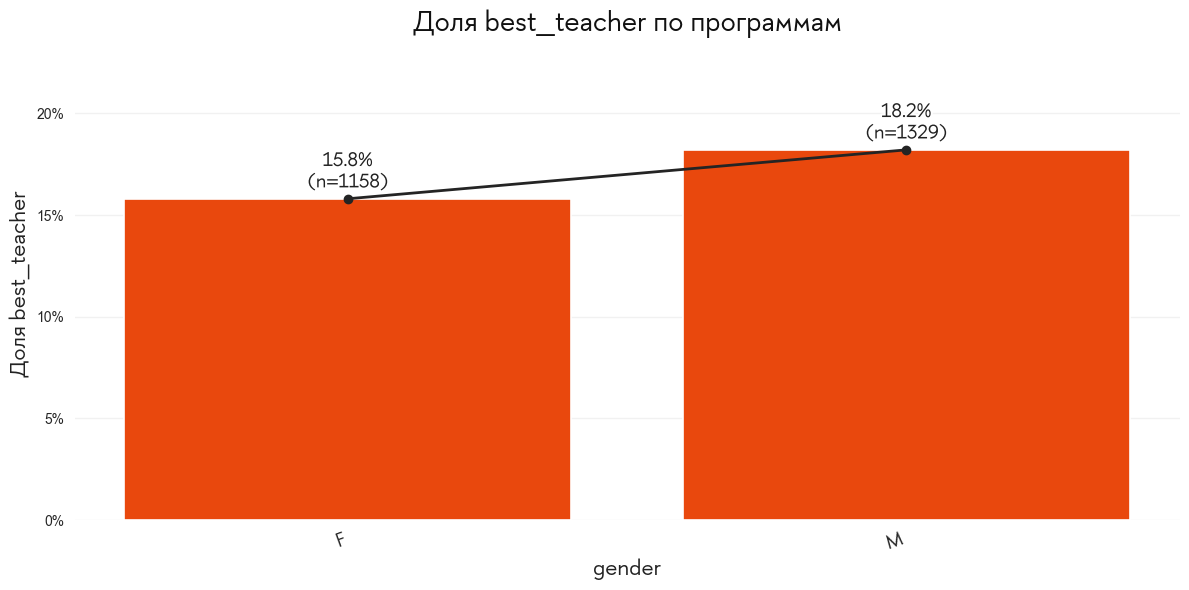

<Axes: title={'center': 'Доля best_teacher по программам'}, xlabel='gender', ylabel='Доля best_teacher'>

In [13]:
plot_best_by(df, x="gender", y="best_teacher", agg="mean",
             orientation="vertical", log_axis="x",  # включи "x" при нужде
             title="Доля best_teacher по программам")

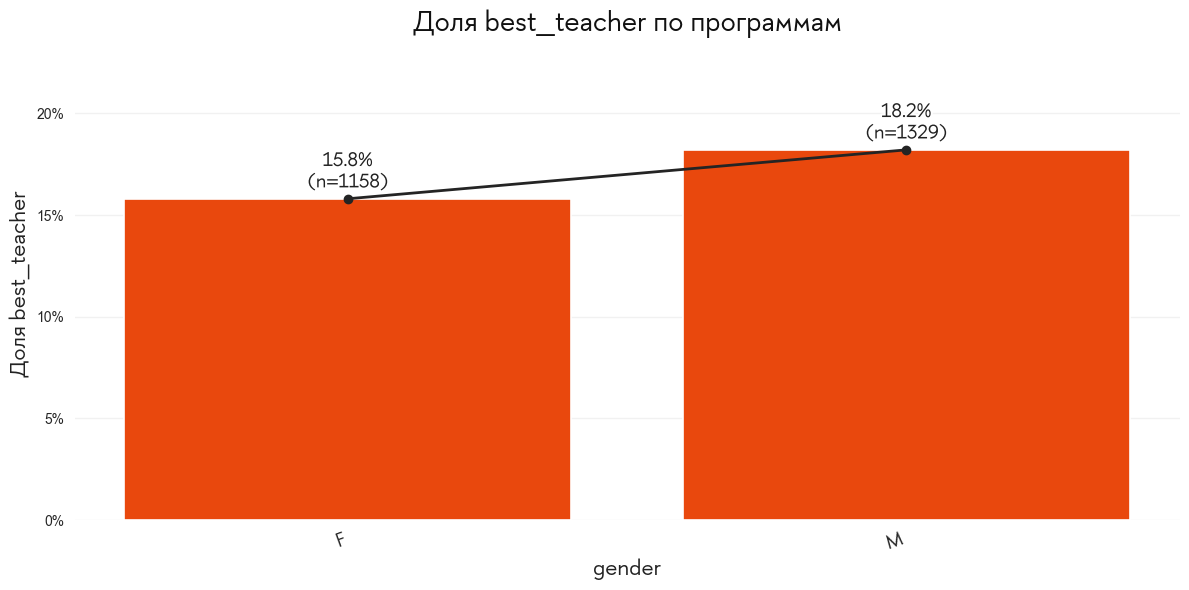

<Axes: title={'center': 'Доля best_teacher по программам'}, xlabel='gender', ylabel='Доля best_teacher'>

In [14]:
plot_best_by(df, x="gender", y="best_teacher", agg="mean",
             orientation="vertical", log_axis="x",  # включи "x" при нужде
             title="Доля best_teacher по программам")

In [15]:
df

,id,year,gender,faculty,teaching_position,position_head,HSE_start,experience_uni,bachelor,specialist,...,thesis_bachelor,thesis_master,PhD_students,PhD_finished,best_teacher,best_teacher_previous,y,deg_has_candidate,deg_has_doctor,deg_has_phd
0,100,y24_25,M,econ,профессор,1,1998,27.0,NaN,1998,...,3,2,2,8,0,6,0,1,0,1
1,100,y23_24,M,econ,профессор,1,1998,26.0,NaN,1998,...,5,0,2,8,0,6,0,1,0,1
2,100,y22_23,M,econ,профессор,1,1998,25.0,NaN,1998,...,0,4,1,8,0,6,0,1,0,1
3,101,y24_25,M,econ,доцент,1,2006,14.0,2005,NaN,...,0,0,1,0,0,2,0,1,0,0
4,101,y23_24,M,econ,доцент,1,2006,13.0,2005,NaN,...,0,0,1,0,0,2,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2482,927,y23_24,M,math,профессор,0,2017,38.0,NaN,1976,...,0,1,0,0,0,3,0,0,1,0
2483,927,y22_23,M,math,профессор,0,2017,37.0,NaN,1976,...,0,2,0,0,0,3,0,0,1,0
2484,928,y24_25,M,math,профессор,1,2011,8.0,NaN,1990,...,1,0,0,0,0,0,0,1,0,0
2485,928,y23_24,M,math,профессор,1,2011,7.0,NaN,1990,...,0,0,0,0,0,0,0,1,0,0


In [43]:
# ================= LOGIT (без L2) — корректные p-values, топ-15 по значимости =================
import numpy as np, pandas as pd, re, warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy.stats import norm

# ---------- 0) Берём готовые dfm/formula/ID_COL, если они уже есть; иначе построим ----------
try:
    _ = dfm, formula
except NameError:
    # резервная подготовка из df
    assert 'df' in globals(), "Положи свой DataFrame в переменную df"
    dfm = df.copy().rename(columns=lambda x: str(x).replace('.', '_'))
    TARGET = 'best_teacher' if 'best_teacher' in dfm.columns else 'y'
    ID_COL = 'id' if 'id' in dfm.columns else None

    # списки признаков (подстроятся под наличие колонок)
    CATS = [c for c in ['gender','faculty','teaching_position','year'] if c in dfm.columns]
    BINS = [c for c in ['publications_english','HSE_graduate','position_head'] if c in dfm.columns]
    NUMS = [c for c in ['thesis_bachelor','thesis_master','PhD_students','PhD_finished','courses_total'] if c in dfm.columns]

    # degree → один понятный флаг
    if 'degree' in dfm.columns:
        dfm['deg_has_phd'] = dfm['degree'].fillna('').astype(str).str.contains(
            r'\bPhD\b|Doctor of Philosophy|доктор философии', case=False, regex=True
        ).astype(int)
        if 'deg_has_phd' not in BINS: BINS.append('deg_has_phd')

    # целевая
    dfm['y'] = pd.to_numeric(dfm[TARGET], errors='coerce').fillna(0).astype(int)

    # простая чистка
    def collapse_rare_levels(s: pd.Series, min_count=20, other_label='Other'):
        vc = s.astype(str).value_counts(dropna=False)
        rare = vc[vc < min_count].index
        return s.astype(str).where(~s.astype(str).isin(rare), other_label)

    for c in CATS:
        dfm[c] = collapse_rare_levels(dfm[c]).fillna('NA')
    for c in NUMS:
        dfm[c] = pd.to_numeric(dfm[c], errors='coerce'); med = dfm[c].median()
        dfm[c] = dfm[c].fillna(med if np.isfinite(med) else 0.0)
    for c in BINS:
        dfm[c] = dfm[c].fillna(0).astype(int)

    rhs = [f"C({c})" for c in CATS] + BINS + NUMS
    formula = "y ~ " + " + ".join(rhs)

print("Formula (no L2):", formula)

# ---------- 1) Ковариационная матрица: кластер по id (если есть), иначе HC1 ----------
ID_COL = 'id' if ('ID_COL' not in globals() and 'id' in dfm.columns) else (ID_COL if 'ID_COL' in globals() else None)
if ID_COL and ID_COL in dfm.columns:
    cov_type = 'cluster'
    cov_kw = {'groups': dfm[ID_COL].values}
else:
    cov_type = 'HC1'
    cov_kw = None

# ---------- 2) Фит без регуляризации (MLE) ----------
def fit_logit_noreg(formula, data, cov_type, cov_kw):
    return smf.logit(formula=formula, data=data).fit(disp=False, cov_type=cov_type, cov_kwds=cov_kw)

try:
    fit_nr = fit_logit_noreg(formula, dfm, cov_type, cov_kw)
except Exception as e:
    # если полная спецификация тяжело сходится — компактная «мини»-формула
    mini_rhs = [r for r in [
        "C(gender)", "C(faculty)", "C(teaching_position)", "C(year)",
        "HSE_graduate", "PhD_students", "courses_total", "thesis_bachelor", "PhD_finished"
    ] if (r.startswith("C(") and r[2:-1] in dfm.columns) or (r in dfm.columns)]
    formula = "y ~ " + " + ".join(mini_rhs)
    print("⚠️ Full model struggled. Fallback to mini formula:", formula)
    fit_nr = fit_logit_noreg(formula, dfm, cov_type, cov_kw)

# ---------- 3) Таблица коэффициентов: β, SE, z, p, ДИ, OR ----------
P  = pd.Series(fit_nr.params, index=fit_nr.params.index)
SE = pd.Series(fit_nr.bse,    index=fit_nr.params.index)
z  = P/SE
p  = 2*norm.sf(np.abs(z))
ci_lo = P - 1.96*SE
ci_hi = P + 1.96*SE
OR = np.exp(P)

coef_tbl = pd.DataFrame({
    'term': P.index, 'beta': P.values, 'OR': OR.values,
    'se': SE.values, 'z': z.values, 'p': p.values,
    'ci_low': ci_lo.values, 'ci_high': ci_hi.values
})

# ---------- 4) Топ-15 по значимости (без Intercept) ----------
top15 = (coef_tbl.query("term != 'Intercept'")
         .sort_values('p', ascending=True)
         .head(15)
         .reset_index(drop=True))

pd.set_option('display.float_format', lambda x: f"{x:0.4f}")
print("\n=== LOGIT (MLE, robust SE) — Top-15 by p-value ===")
print(top15[['term','beta','OR','se','z','p','ci_low','ci_high']].to_string(index=False))

# ---------- 5) (Опционально) AME — средние маржинальные эффекты в п.п. ----------
# ame = fit_nr.get_margeff(at='overall').summary_frame()
# print("\n=== Average Marginal Effects (п.п.) ===")
# print(ame[['dy/dx','Std. Err.','z','P>|z|','[0.025','0.975]']].rename(
#     columns={'dy/dx':'AME','Std. Err.':'SE','P>|z|':'p','[0.025':'ci_low', '0.975]':'ci_high'}
# ).to_string())


Formula (no L2): y ~ C(gender) + C(faculty) + C(teaching_position) + C(year) + publications_english + HSE_graduate + position_head + deg_has_phd + thesis_bachelor + thesis_master + PhD_students + PhD_finished + courses_total


AttributeError: 'numpy.ndarray' object has no attribute 'values'

In [16]:
df['involvement_index'] = (
        df['courses_total'].fillna(0)
        + df['courses_minor'].fillna(0)
        + df['courses_magolego'].fillna(0)
        + df['thesis_bachelor'].fillna(0)
        + df['thesis_master'].fillna(0)
        + df['PhD_students'].fillna(0)
)


In [17]:
import statsmodels.formula.api as smf

fit = smf.logit('best_teacher ~ involvement_index', data=df).fit()
print(fit.summary())


Optimization terminated successfully.
         Current function value: 0.436231
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:           best_teacher   No. Observations:                 2487
Model:                          Logit   Df Residuals:                     2485
Method:                           MLE   Df Model:                            1
Date:                Sun, 12 Oct 2025   Pseudo R-squ.:                 0.04606
Time:                        11:44:28   Log-Likelihood:                -1084.9
converged:                       True   LL-Null:                       -1137.3
Covariance Type:            nonrobust   LLR p-value:                 1.380e-24
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept            -2.1383      0.082    -25.971      0.000      -2.300      -1.977
involvem

In [18]:
fit = smf.logit(
    'best_teacher ~ involvement_index + C(gender) + C(faculty) + experience_uni',
    data=df
).fit()
print(fit.summary())


Optimization terminated successfully.
         Current function value: 0.432435
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:           best_teacher   No. Observations:                 2487
Model:                          Logit   Df Residuals:                     2481
Method:                           MLE   Df Model:                            5
Date:                Sun, 12 Oct 2025   Pseudo R-squ.:                 0.05436
Time:                        11:44:29   Log-Likelihood:                -1075.5
converged:                       True   LL-Null:                       -1137.3
Covariance Type:            nonrobust   LLR p-value:                 5.307e-25
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept              -2.3493      0.159    -14.816      0.000      -2.660      -2.038
C(

In [19]:
fit = smf.logit(
    'best_teacher ~ courses_minor + courses_magolego + thesis_bachelor + thesis_master + PhD_students + courses_total',
    data=df
).fit()
print(fit.summary())


Optimization terminated successfully.
         Current function value: 0.431686
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:           best_teacher   No. Observations:                 2487
Model:                          Logit   Df Residuals:                     2480
Method:                           MLE   Df Model:                            6
Date:                Sun, 12 Oct 2025   Pseudo R-squ.:                 0.05600
Time:                        11:44:29   Log-Likelihood:                -1073.6
converged:                       True   LL-Null:                       -1137.3
Covariance Type:            nonrobust   LLR p-value:                 4.605e-25
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept           -2.3419      0.095    -24.567      0.000      -2.529      -2.155
courses_min

In [42]:
def plot_best_by(
        df=None,
        col=None,
        series=None,
        title=None,
        filename=None,
        show_trend=True,
        sort_by="index",
        ascending=True,
        rotation=20,
        nan_policy="drop",     # как обращаться с NaN в целевой (drop|zero) — для бинарной лучше drop
        nan_category="drop",   # как учитывать NaN в категориальной
        ylim=None,
        show_count=True,       # показывать (n=...)
        as_percent=True        # показывать долю в процентах
):
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    import matplotlib.patheffects as path_effects
    import os
    from matplotlib.font_manager import FontProperties, fontManager

    # ==== Шрифт HSE Sans ====
    FONT_DIR = r"C:\Users\coldn\Downloads\HSE Sans"  # при необходимости поправь путь

    def _resolve_font(*names):
        for name in names:
            path = os.path.join(FONT_DIR, name)
            if os.path.exists(path):
                return path
        raise FileNotFoundError("Не найден файл HSE Sans. Проверь FONT_DIR.")

    regular_font_path = _resolve_font("HSESans-Regular.otf", "HSESans-Regular.ttf")
    try:
        fontManager.addfont(regular_font_path)
    except Exception:
        pass

    # набор FontProperties
    font_prop_small  = FontProperties(fname=regular_font_path, size=12)
    font_prop_base   = FontProperties(fname=regular_font_path, size=14)
    font_prop_large  = FontProperties(fname=regular_font_path, size=16)
    font_prop_title  = FontProperties(fname=regular_font_path, size=20)

    # ==== Цвета ====
    MAIN_BEET    = "#93E9BE"  # столбцы
    MAIN_SEAFOAM = "#8A1653"  # линия тренда
    ACCENT_GRAY  = "#E9E9E9"  # сетка

    # ---- входные данные ----
    if series is None:
        if df is None or col is None:
            raise ValueError("Передай либо df+col, либо series.")
        series = df[col]
    else:
        col = series.name if series.name is not None else "feature"

    if df is None or "best_teacher" not in df.columns:
        raise ValueError("Нужен df с колонкой 'best_teacher' (0/1).")

    # Собираем рабочий датафрейм
    d = pd.DataFrame({col: series, "best_teacher": df["best_teacher"]}).copy()

    # обработка NaN в целевой
    if nan_policy == "zero":
        d["best_teacher"] = d["best_teacher"].fillna(0).astype(float)
    else:
        d = d.dropna(subset=["best_teacher"])
    # приводим к 0/1
    d["best_teacher"] = (d["best_teacher"].astype(float) > 0).astype(int)

    # обработка NaN в категориальном столбце
    if nan_category == "drop":
        d = d.dropna(subset=[col])
    else:
        d[col] = d[col].astype(object).where(d[col].notna(), "NaN")

    d["_cat"] = d[col].astype(str)

    # агрегирование: mean = доля лучших, n = объём
    agg = d.groupby("_cat").agg(
        best_rate=("best_teacher", "mean"),
        n=("best_teacher", "size")
    ).reset_index().rename(columns={"_cat": "category"})

    # сортировка
    if sort_by == "mean":
        agg = agg.sort_values("best_rate", ascending=ascending)
    elif sort_by == "count":
        agg = agg.sort_values("n", ascending=ascending)
    else:
        agg = agg.sort_values("category", ascending=ascending)

    # подготавливаем данные
    categories = agg["category"].tolist()
    x = np.arange(len(categories))
    y = agg["best_rate"].values.astype(float)

    # проценты для подписи/оси
    def fmt_val(v):
        return f"{v*100:.1f}%" if as_percent else f"{v:.3f}"

    fig, ax = plt.subplots(figsize=(12, 6), dpi=100, facecolor="white")

    bars = ax.bar(
        x,
        y if not as_percent else y,  # данные остаются в [0,1]; форматируем в подписях/оси
        color=MAIN_BEET,
        edgecolor="white",
        linewidth=1.2
    )

    # подписи над барами
    ymax = np.nanmax(y) if len(agg) else 1.0
    pad = 0.02 * (ymax if ymax > 0 else 1)
    for rect, mean_val, cnt in zip(bars, y, agg["n"].values):
        if not np.isnan(mean_val):
            label = fmt_val(mean_val)
            if show_count:
                label += f"\n(n={int(cnt)})"
            ax.text(
                rect.get_x() + rect.get_width()/2,
                rect.get_height() + pad,
                label,
                ha="center", va="bottom",
                fontproperties=font_prop_base, color="#222222",
                linespacing=1.0,
                path_effects=[path_effects.withStroke(linewidth=3, foreground="white")]
            )

    if show_trend and len(agg) > 1:
        ax.plot(x, y, marker='o', linewidth=2, color=MAIN_SEAFOAM)

    # оформление
    ax.set_facecolor("#FFFFFF")
    ax.grid(axis="y", color=ACCENT_GRAY, linewidth=1, alpha=0.6)
    ax.set_axisbelow(True)

    ax.set_xticks(x)
    ax.set_xticklabels(categories, rotation=rotation, ha="right", fontproperties=font_prop_base)
    ax.set_xlabel(col, fontproperties=font_prop_large, color="#222")

    # ось Y: подпишем как долю / процент
    ax.set_ylabel("Доля лучших преподавателей" + (" (%)" if as_percent else ""),
                  fontproperties=font_prop_large, color="#222")
    if as_percent:
        # показываем в процентах (0–100), но данные в [0,1]
        from matplotlib.ticker import FuncFormatter
        ax.yaxis.set_major_formatter(FuncFormatter(lambda v, pos: f"{v*100:.0f}%"))

    ax.set_title(title or f"Доля best_teacher по значениям {col}",
                 fontproperties=font_prop_title, color="#111", pad=12)

    # лимиты
    if ylim is not None:
        # если проценты передали как (0,100), переведём в [0,1]
        if as_percent and (ylim[1] > 1 or ylim[0] > 1):
            ax.set_ylim(ylim[0]/100.0, ylim[1]/100.0)
        else:
            ax.set_ylim(*ylim)
    else:
        # аккуратный верхний отступ
        ax.set_ylim(0, min(1.0, ymax + max(0.05, 0.1*ymax)))

    plt.tight_layout()
    if filename:
        plt.savefig(filename, bbox_inches="tight", dpi=300)
        print(f"График сохранён в {filename}")
    plt.show()


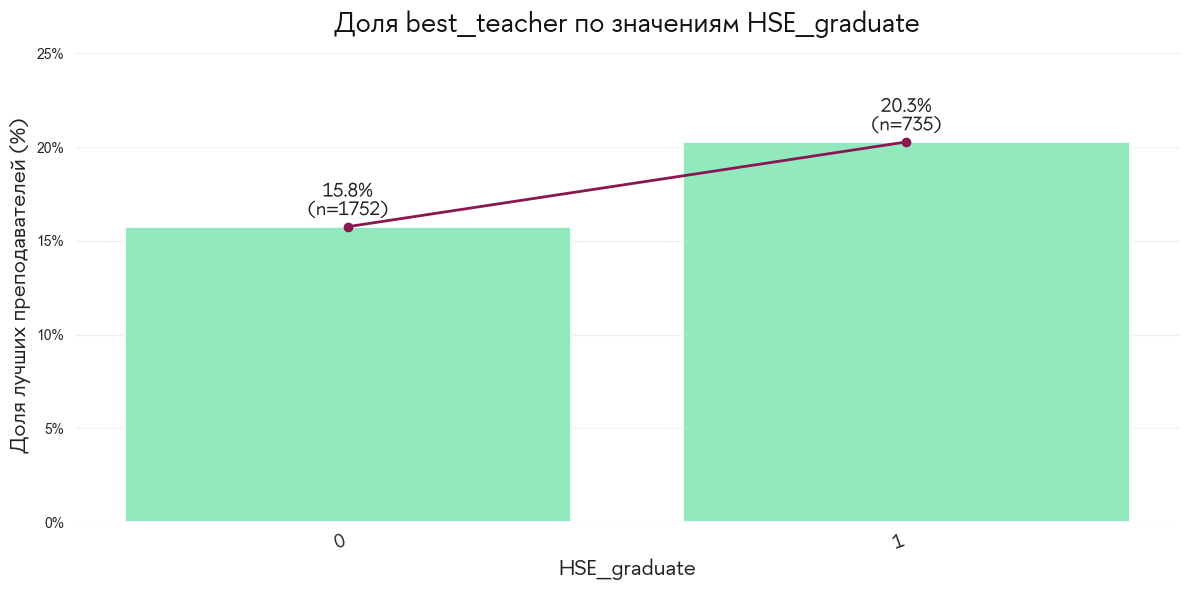

In [21]:
plot_best_by(df=df, col="HSE_graduate", sort_by="count", ascending=False)

In [22]:
df

,id,year,gender,faculty,teaching_position,position_head,HSE_start,experience_uni,bachelor,specialist,...,thesis_master,PhD_students,PhD_finished,best_teacher,best_teacher_previous,y,deg_has_candidate,deg_has_doctor,deg_has_phd,involvement_index
0,100,y24_25,M,econ,профессор,1,1998,27.0,NaN,1998,...,2,2,8,0,6,0,1,0,1,12
1,100,y23_24,M,econ,профессор,1,1998,26.0,NaN,1998,...,0,2,8,0,6,0,1,0,1,12
2,100,y22_23,M,econ,профессор,1,1998,25.0,NaN,1998,...,4,1,8,0,6,0,1,0,1,10
3,101,y24_25,M,econ,доцент,1,2006,14.0,2005,NaN,...,0,1,0,0,2,0,1,0,0,2
4,101,y23_24,M,econ,доцент,1,2006,13.0,2005,NaN,...,0,1,0,0,2,0,1,0,0,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2482,927,y23_24,M,math,профессор,0,2017,38.0,NaN,1976,...,1,0,0,0,3,0,0,1,0,5
2483,927,y22_23,M,math,профессор,0,2017,37.0,NaN,1976,...,2,0,0,0,3,0,0,1,0,8
2484,928,y24_25,M,math,профессор,1,2011,8.0,NaN,1990,...,0,0,0,0,0,0,1,0,0,2
2485,928,y23_24,M,math,профессор,1,2011,7.0,NaN,1990,...,0,0,0,0,0,0,1,0,0,1


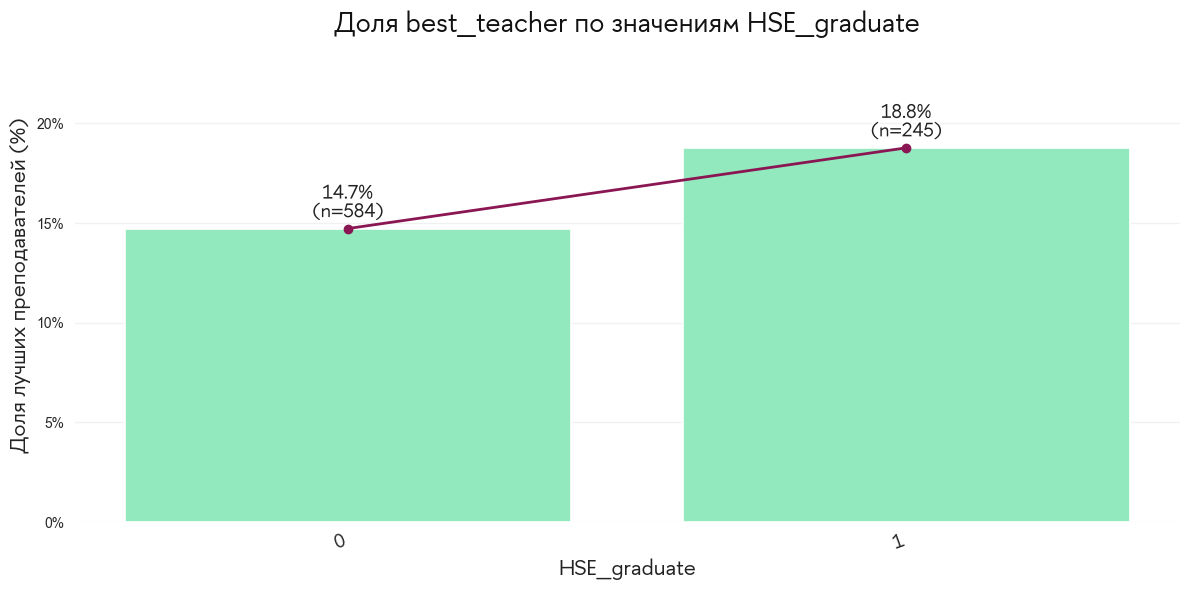

In [23]:
# Схлопываем повторы по id в одну строку.
# Для всех столбцов берём первый попавшийся (first),
# а для HSE_graduate — максимум (т.е. 1, если была хотя бы в одной строке).

cols = list(df.columns)
assert 'id' in cols and 'HSE_graduate' in cols, "Нужны колонки 'id' и 'HSE_graduate'"

agg_dict = {c: 'first' for c in cols if c != 'HSE_graduate'}
agg_dict['HSE_graduate'] = 'max'

df_uniq = df.groupby('id', as_index=False).agg(agg_dict)
plot_best_by(df=df_uniq, col="HSE_graduate", sort_by="count", ascending=False)

In [24]:
df_uniq

,id,year,gender,faculty,teaching_position,position_head,HSE_start,experience_uni,bachelor,specialist,...,PhD_students,PhD_finished,best_teacher,best_teacher_previous,y,deg_has_candidate,deg_has_doctor,deg_has_phd,involvement_index,HSE_graduate
0,100,y24_25,M,econ,профессор,1,1998,27.0,None,1998,...,2,8,0,6,0,1,0,1,12,1
1,101,y24_25,M,econ,доцент,1,2006,14.0,2005,None,...,1,0,0,2,0,1,0,0,2,1
2,102,y24_25,F,econ,доцент,1,2001,24.0,1998;1998,None,...,0,0,0,9,0,1,0,0,8,1
3,103,y24_25,F,econ,доцент,1,1998,43.0,None,1979,...,0,0,0,6,0,1,0,0,1,0
4,104,y24_25,F,econ,доцент,1,2017,13.0,2010,None,...,0,0,0,3,0,0,0,1,13,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
824,924,y24_25,F,math,доцент,0,2014,11.0,None,None,...,0,0,0,4,0,1,0,0,8,0
825,925,y24_25,M,math,доцент,0,2011,14.0,None,2008,...,1,0,0,6,0,1,0,0,4,1
826,926,y24_25,F,math,доцент,1,2024,17.0,None,1995,...,0,0,0,0,0,1,0,0,8,0
827,927,y24_25,M,math,профессор,0,2017,39.0,None,1976,...,0,0,0,3,0,0,1,0,14,0


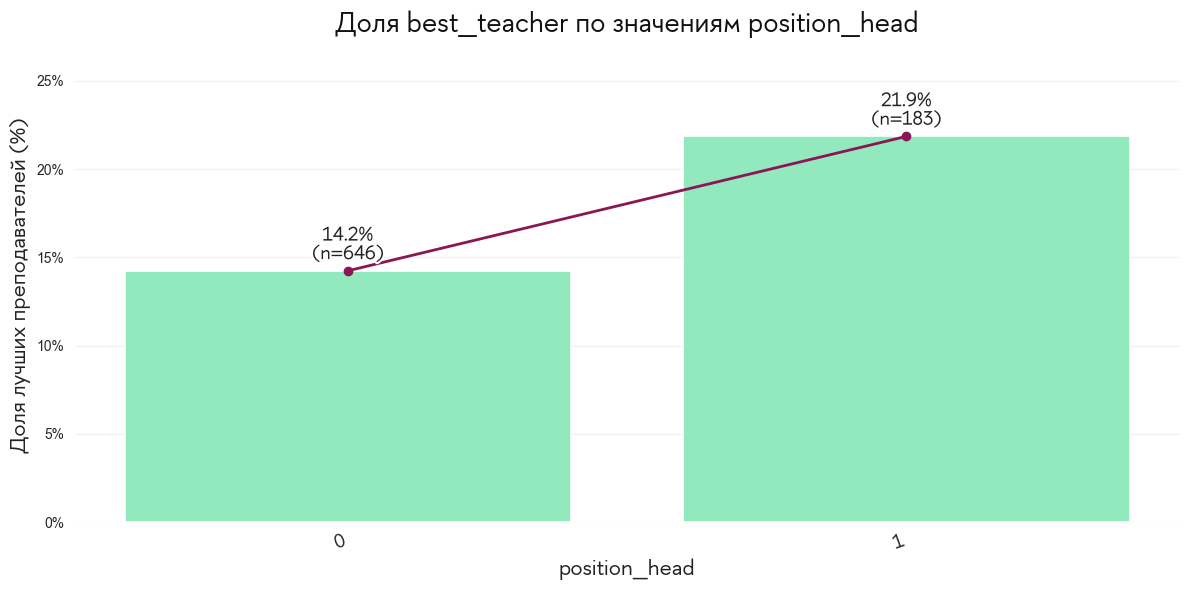

In [25]:
df_uniq_hse = df_uniq[df_uniq['HSE_graduate'] == 1]
plot_best_by(df=df_uniq, col="position_head", sort_by="count", ascending=False)


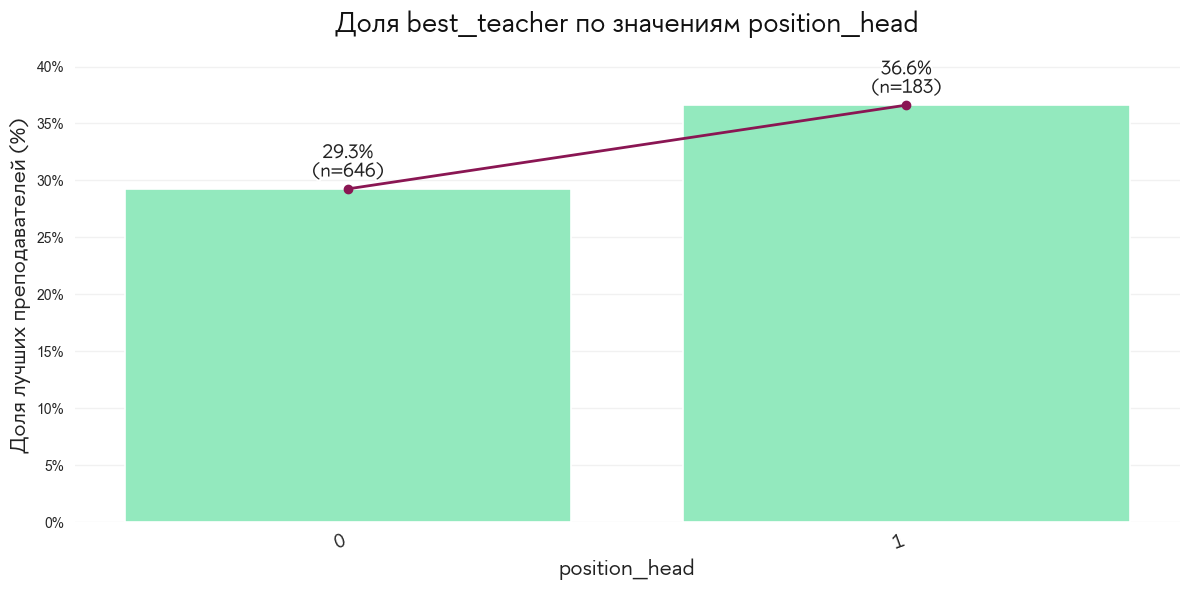

In [26]:
# Схлопываем повторы по id в одну строку.
# Для всех столбцов берём первый попавшийся (first),
# а для HSE_graduate — максимум (т.е. 1, если была хотя бы в одной строке).

cols = list(df.columns)
assert 'id' in cols and 'HSE_graduate' in cols, "Нужны колонки 'id' и 'HSE_graduate'"

agg_dict = {c: 'max' for c in cols if c != 'HSE_graduate' if c != 'position_head' if c != 'best_teacher_previous'}
agg_dict['HSE_graduate'] = 'max'
agg_dict['position_head'] = 'max'
agg_dict['best_teacher_previous'] = 'max'
df_uniq = df.groupby('id', as_index=False).agg(agg_dict)
plot_best_by(df=df_uniq, col="position_head", sort_by="count", ascending=False)


                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                 1740
Model:                          Logit   Df Residuals:                     1714
Method:                           MLE   Df Model:                           25
Date:                Sun, 12 Oct 2025   Pseudo R-squ.:                  0.1194
Time:                        11:44:32   Log-Likelihood:                -691.76
converged:                       True   LL-Null:                       -785.58
Covariance Type:              cluster   LLR p-value:                 7.133e-27
                                                         coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------------------------
Intercept                                             -1.8341      1.309     -1.401      0.161      -4.400       0.732
C(gender)[T

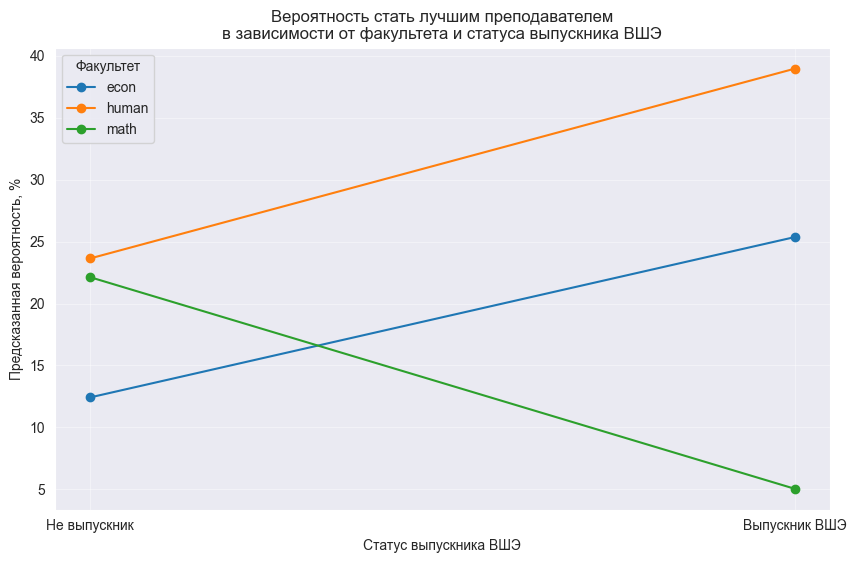

In [27]:
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# === 1) Формула с взаимодействием ===
formula_inter = (
    "y ~ C(gender) + C(faculty) + C(teaching_position) + C(year) "
    "+ HSE_graduate * C(faculty) "
    "+ publications_english + position_head + experience_uni "
    "+ publications_papers_5years + publications_other_5years + paper_award "
    "+ courses_total + thesis_bachelor + thesis_master + PhD_students + PhD_finished"
)

fit_inter = smf.logit(formula=formula_inter, data=train_df).fit(
    disp=False, cov_type="cluster", cov_kwds={"groups": train_df["id"].values}
)
print(fit_inter.summary())

# === 2) Предсказания для комбинаций faculty × HSE_graduate ===
faculties = sorted(train_df["faculty"].unique())
pred_data = pd.DataFrame({
    "faculty": np.repeat(faculties, 2),
    "HSE_graduate": [0, 1] * len(faculties)
})

# Заполняем контрольные переменные средними/базовыми
for col in ['experience_uni','publications_papers_5years','publications_other_5years',
            'paper_award','courses_total','thesis_bachelor','thesis_master','PhD_students','PhD_finished']:
    if col in train_df.columns:
        pred_data[col] = train_df[col].mean()

# Категориальные без взаимодействий — берём базовые категории
for col in ['gender','teaching_position','year']:
    if col in train_df.columns:
        pred_data[col] = train_df[col].mode()[0]

pred_data['publications_english'] = 0
pred_data['position_head'] = 0

pred_data["predicted_prob"] = fit_inter.predict(pred_data)

# === 3) График ===
plt.figure(figsize=(10,6))
for fac in faculties:
    subset = pred_data[pred_data["faculty"] == fac]
    plt.plot(["Не выпускник", "Выпускник ВШЭ"],
             subset["predicted_prob"]*100,
             marker="o", label=fac)

plt.title("Вероятность стать лучшим преподавателем\nв зависимости от факультета и статуса выпускника ВШЭ")
plt.ylabel("Предсказанная вероятность, %")
plt.xlabel("Статус выпускника ВШЭ")
plt.legend(title="Факультет")
plt.grid(alpha=0.4)
plt.show()


In [28]:
df

,id,year,gender,faculty,teaching_position,position_head,HSE_start,experience_uni,bachelor,specialist,...,thesis_master,PhD_students,PhD_finished,best_teacher,best_teacher_previous,y,deg_has_candidate,deg_has_doctor,deg_has_phd,involvement_index
0,100,y24_25,M,econ,профессор,1,1998,27.0,NaN,1998,...,2,2,8,0,6,0,1,0,1,12
1,100,y23_24,M,econ,профессор,1,1998,26.0,NaN,1998,...,0,2,8,0,6,0,1,0,1,12
2,100,y22_23,M,econ,профессор,1,1998,25.0,NaN,1998,...,4,1,8,0,6,0,1,0,1,10
3,101,y24_25,M,econ,доцент,1,2006,14.0,2005,NaN,...,0,1,0,0,2,0,1,0,0,2
4,101,y23_24,M,econ,доцент,1,2006,13.0,2005,NaN,...,0,1,0,0,2,0,1,0,0,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2482,927,y23_24,M,math,профессор,0,2017,38.0,NaN,1976,...,1,0,0,0,3,0,0,1,0,5
2483,927,y22_23,M,math,профессор,0,2017,37.0,NaN,1976,...,2,0,0,0,3,0,0,1,0,8
2484,928,y24_25,M,math,профессор,1,2011,8.0,NaN,1990,...,0,0,0,0,0,0,1,0,0,2
2485,928,y23_24,M,math,профессор,1,2011,7.0,NaN,1990,...,0,0,0,0,0,0,1,0,0,1


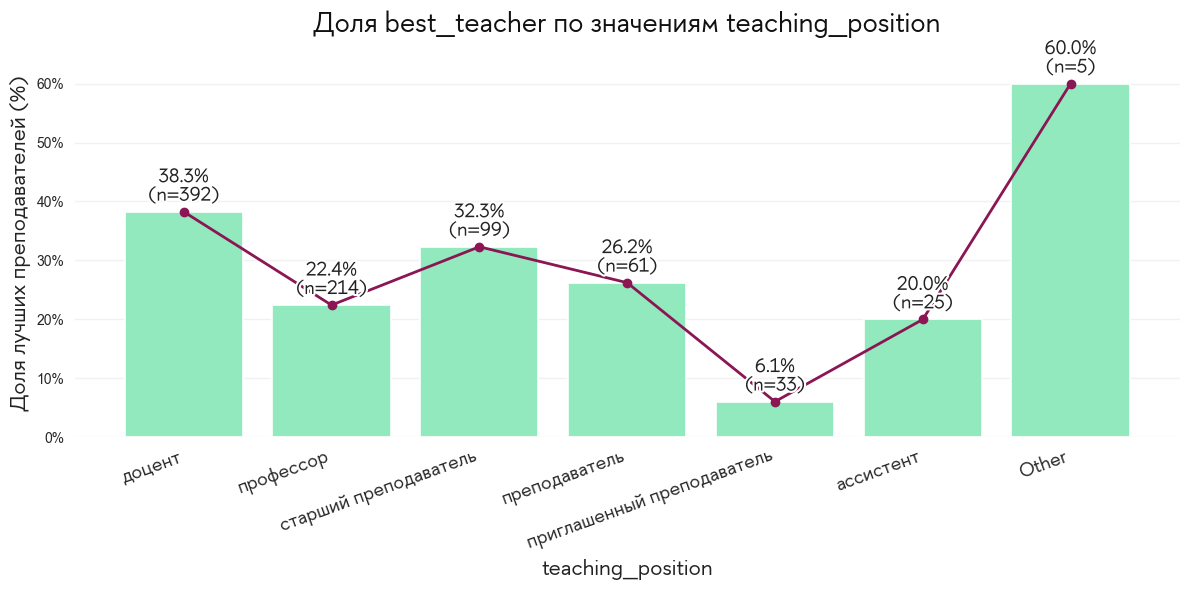

In [29]:
df_uniq_hse = df_uniq[df_uniq['HSE_graduate'] == 1]
plot_best_by(df=df_uniq, col="teaching_position", sort_by="count", ascending=False)


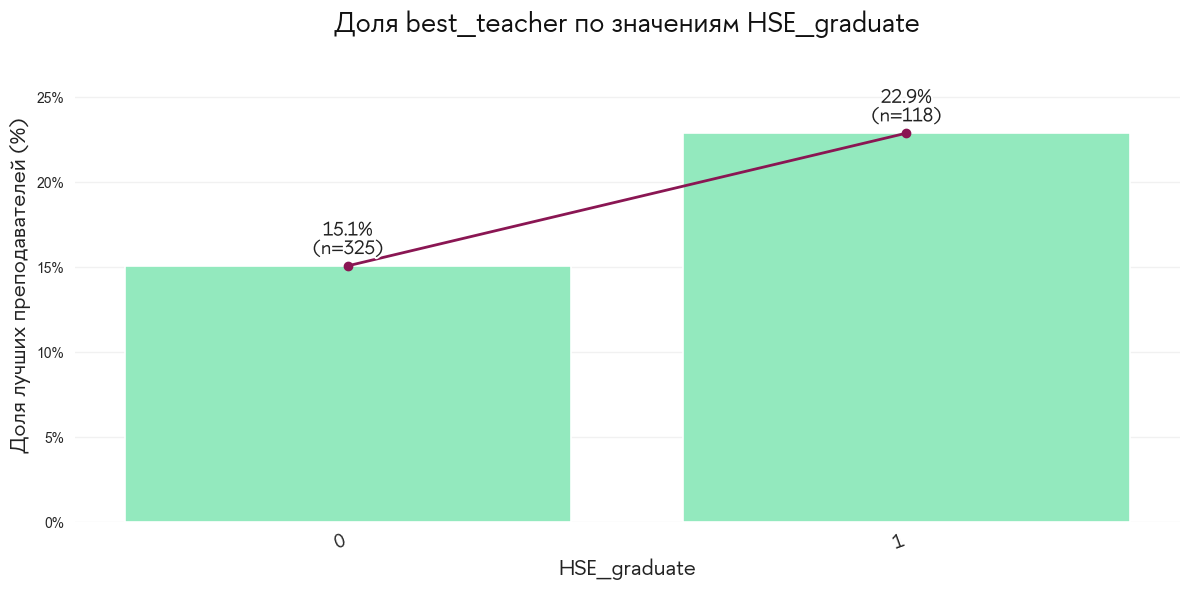

In [30]:
# Схлопываем повторы по id в одну строку.
# Для всех столбцов берём первый попавшийся (first),
# а для HSE_graduate — максимум (т.е. 1, если была хотя бы в одной строке).

cols = list(df.columns)
assert 'id' in cols and 'HSE_graduate' in cols, "Нужны колонки 'id' и 'HSE_graduate'"

agg_dict = {c: 'first' for c in cols if c != 'HSE_graduate'}
agg_dict['HSE_graduate'] = 'max'

df_uniq = df.groupby('id', as_index=False).agg(agg_dict)
plot_best_by(df=df_uniq[df_uniq["gender"] == "M"], col="HSE_graduate", sort_by="count", ascending=False)

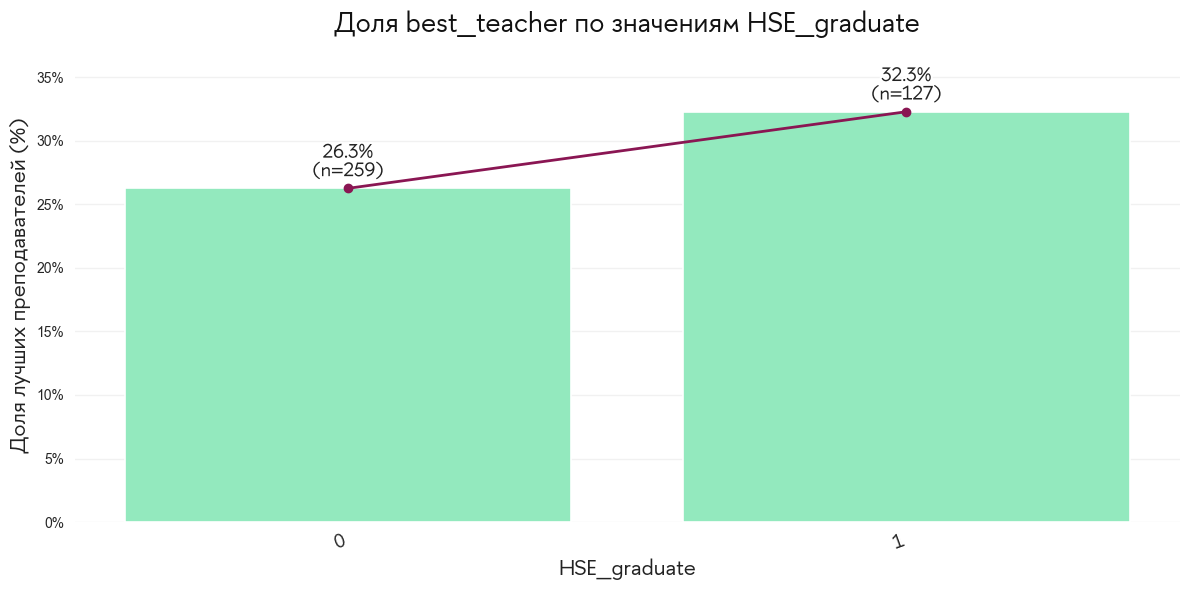

In [31]:
# Схлопываем повторы по id в одну строку.
# Для всех столбцов берём первый попавшийся (first),
# а для HSE_graduate — максимум (т.е. 1, если была хотя бы в одной строке).

cols = list(df.columns)
assert 'id' in cols and 'HSE_graduate' in cols, "Нужны колонки 'id' и 'HSE_graduate'"

agg_dict = {c: 'max' for c in cols if c != 'HSE_graduate'}
agg_dict['HSE_graduate'] = 'max'

df_uniq = df.groupby('id', as_index=False).agg(agg_dict)
plot_best_by(df=df_uniq[df_uniq["gender"] == "F"], col="HSE_graduate", sort_by="count", ascending=False)